Testing the efficacy of network diffusion models to model Tau and TDP43 pathologies in behavioral frontotemporal lobe dementia (bvFTD) using histopathological laminar covariance networks as a scaffold.

In [205]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests, fdrcorrection


# 1. Load networks from precomputed covariance data

Data provided by Dan Ohm from a covariance study they did previously.

Laminar layers L23/L56 serve as nodes in the network, across 11 cortical subregions, totaling 22 nodes in the network.

In [2]:
HC_SMI32_sig_network = pd.read_excel('HC_networks_102226.xlsx', sheet_name='SMI32_HC_sig')
node_atlas = HC_SMI32_sig_network.columns[1:].to_numpy()
HC_SMI32_sig_network = HC_SMI32_sig_network[node_atlas].fillna(0).to_numpy()
HC_SMI32_sig_network[HC_SMI32_sig_network<0] = 0

HC_NeuN_sig_network = pd.read_excel('HC_networks_102226.xlsx', sheet_name='NeuN_HC_sig')
HC_NeuN_sig_network = HC_NeuN_sig_network[node_atlas].fillna(0).to_numpy()
HC_NeuN_sig_network[HC_NeuN_sig_network<0] = 0

HC_SMI32_network = pd.read_excel('HC_networks_102226.xlsx', sheet_name='SMI32_HC')
HC_SMI32_network = HC_SMI32_network[node_atlas].fillna(0).to_numpy()
HC_SMI32_network[HC_SMI32_network<0] = 0

HC_NeuN_network = pd.read_excel('HC_networks_102226.xlsx', sheet_name='NeuN_HC')
HC_NeuN_network = HC_NeuN_network[node_atlas].fillna(0).to_numpy()
HC_NeuN_network[HC_NeuN_network<0] = 0

print(HC_SMI32_sig_network.shape)
print(HC_NeuN_sig_network.shape)

print(node_atlas)

(22, 22)
(22, 22)
['L23_1' 'L23_2' 'L23_3' 'L23_4' 'L23_5' 'L23_6' 'L23_7' 'L23_8' 'L23_9'
 'L23_10' 'L23_11' 'L56_1' 'L56_2' 'L56_3' 'L56_4' 'L56_5' 'L56_6' 'L56_7'
 'L56_8' 'L56_9' 'L56_10' 'L56_11']


## 1.1 Load the tau data

Notes: tau data are split into 2 sets of layers due to the staining procedure, L123 and L456. This works well with the data since we are looking at L23 and L56, however we will have to note that there is some noise due to L1 and L4 being lumped into the tau data as well.

These are separated by group (HC, TDP, TAU). These are subject-wise, so population averaging can be done.

In [3]:
tau_patho = pd.read_excel('Path_measurements_102226-nonlog.xlsx', sheet_name='Path_TAU')
tdp_patho = pd.read_excel('Path_measurements_102226-nonlog.xlsx', sheet_name='Path_TDP')


In [4]:
tau_patho_avg = np.nanmean(tau_patho[tau_patho.columns[1:]], axis=0)
tdp_patho_avg = np.nanmean(tdp_patho[tdp_patho.columns[1:]], axis=0)

# Double check shape and vector values
print(tau_patho_avg.shape)
print(tau_patho_avg)

print(tdp_patho_avg.shape)
print(tdp_patho_avg)

(22,)
[0.02257659 0.02504287 0.02500266 0.02693315 0.02922994 0.01778203
 0.01968193 0.01871329 0.0204483  0.01558789 0.02349205 0.02952931
 0.03043329 0.03190724 0.03230214 0.03121724 0.02047683 0.01955418
 0.02196644 0.02152182 0.02012328 0.0268189 ]
(22,)
[0.00536802 0.00403111 0.00313649 0.00273078 0.00250603 0.00410642
 0.00366547 0.00382908 0.00356985 0.00270876 0.00240305 0.00366952
 0.00236875 0.002062   0.00187761 0.00209923 0.00222034 0.00211357
 0.00235036 0.00234887 0.00197504 0.00163707]


# 2. Network diffusion - population level

This uses the same overall code as the work from my ACM 2025 paper [1] and follows the network diffusion procedure from [2].

1. Frederick H. Xu, Duy Duong-Tran, Heng Huang, Andrew Saykin, Paul Thompson, Christos Davatzikos, Yize Zhao, and Li Shen. 2025. Characterizing Amyloid Pathogenic Spread in Alzheimer’s Disease Through A Network Diffusion Model. In Proceedings of the 16th ACM International Conference on Bioinformatics, Computational Biology, and Health Informatics (BCB '25). Association for Computing Machinery, New York, NY, USA, Article 17, 1–9. https://doi.org/10.1145/3765612.3767223

2. Thompson E, Schroder A, He T, et al. Combining multimodal connectivity information improves modelling of pathology spread in Alzheimer's disease. Imaging Neurosci (Camb). 2024;2:1-19. Published 2024 Feb 5. doi:10.1162/imag_a_00089

The solution version of the network diffusion equation is $x(t) = e^{-\beta \textbf{H} t} x_0$ where $\textbf{H}$ is the graph laplacian and $x_0$ is the seed, initialized at 1 at the seed and 0 elsewhere. Following the procedure in [2], $x(t)$ is normalized such that the values fall between [0,1].

In [5]:
from scipy.sparse.csgraph import laplacian
from scipy.linalg import expm
from scipy.stats import linregress

In [125]:
def diffusion_func(t, B, H, seed_idx, normalize_dist=True):
    # Set the seed
    x_0 = np.zeros(len(H))
    x_0[seed_idx] = 1

    x_t_dist = np.matmul(expm(-1*B*H*t), x_0)

    # Normalize such that the values fall between [0,1]
    if normalize_dist:
        x_t_dist = x_t_dist/np.max(np.abs(x_t_dist))

    return x_t_dist

# Compute SSE
def SSE(x, y):
    return np.sum((y-x)**2)

# Function to compute performance
def compute_performance(x, y, norm=True):
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    if norm:
        SSE_val = SSE(x/np.max(np.abs(x)), y/np.max(np.abs(y)))
    else:
        SSE_val = SSE(x, y)
        
    return {'slope':slope, 'int':intercept, 'pearsonr':r_value, 'p_val':p_value, 'std_err':std_err, 'SSE':SSE_val}

# Optimize across seed regions
def optimize_spread(subj_net, 
                    subj_pet_vec, 
                    seeds=range(len(node_atlas)), 
                    B=0.0025, 
                    t_iter=300, 
                    t_step=5, 
                    optim_metric='pearsonr', 
                    normalize_net=False,
                    normalize_dist=True,
                    return_all=False
                    ):

    if normalize_net:
        subj_net_rowsums = subj_net.sum(axis=1)
        subj_net_normalize = subj_net / subj_net_rowsums[:, np.newaxis]
        H = laplacian(subj_net_normalize)
    else:
        H = laplacian(subj_net)

    # Optimization
    r_seed_time = []
    r_eval_seed_time = []
    r_evalp_seed_time = []
    for seed in seeds:
        r_t = []
        r_eval_t = []
        r_evalp_t = []
        for t in range(2, t_iter, t_step):
            x_t = diffusion_func(t, B, H, seed_idx=seed, normalize_dist=normalize_dist)
            if optim_metric == 'pearsonr':
                r_t.append(compute_performance(x_t, subj_pet_vec, norm=False)[optim_metric])
                r_eval_t.append(compute_performance(x_t, subj_pet_vec, norm=False)['pearsonr'])
                r_evalp_t.append(compute_performance(x_t, subj_pet_vec, norm=False)['p_val'])
            if optim_metric == 'SSE':
                r_t.append(compute_performance(x_t, subj_pet_vec, norm=True)[optim_metric])
                r_eval_t.append(compute_performance(x_t, subj_pet_vec, norm=True)['pearsonr'])
                r_evalp_t.append(compute_performance(x_t, subj_pet_vec, norm=True)['p_val'])
                
        r_seed_time.append(r_t)
        r_eval_seed_time.append(r_eval_t)
        r_evalp_seed_time.append(r_evalp_t)
        
    r_seed_time = np.array(r_seed_time)
    r_eval_seed_time = np.array(r_eval_seed_time)
    # Minimize SSE
    if optim_metric == 'SSE':
        best_seed_ind, best_time_ind = np.unravel_index(r_seed_time.argmin(), r_seed_time.shape)
    # Maximize Pearson's R
    if optim_metric == 'pearsonr':
        best_seed_ind, best_time_ind = np.unravel_index(r_seed_time.argmax(), r_seed_time.shape)
    # Maximize a combined metric of pearson's R + 1/SSE
    if optim_metric == 'combined':
        best_seed_ind, best_time_ind = np.unravel_index(r_seed_time.argmax(), r_seed_time.shape)

    best_time = np.arange(2,t_iter,t_step)[best_time_ind]
    
    best_x_t = diffusion_func(best_time, B, H, seed_idx=best_seed_ind, normalize_dist=normalize_dist)
    if return_all:
        return best_seed_ind, best_time, best_x_t, r_seed_time, r_eval_seed_time, r_evalp_seed_time
    else:
        return best_seed_ind, best_time, best_x_t

In [30]:
def plot_diffusion_result(sim_spread, avg_pathology, group, color_scatter, color_line):
    seed, time, optim_x_t = sim_spread
    performance = compute_performance(optim_x_t/np.max(optim_x_t), avg_pathology/np.max(avg_pathology))
    plt.figure()
    plt.scatter(optim_x_t/np.max(optim_x_t), avg_pathology/np.max(avg_pathology), color=color_scatter)

    plt.title(group + ' diffusion results, seed=(' + str(node_atlas[seed]) + '), r=' + str(performance['pearsonr'])[0:4], y=1.02, fontsize=18)
    patho_name = group.split()[0]
    plt.ylabel('Ground truth ' + patho_name + '\n distribution (normed)', fontsize=16, labelpad=15)
    plt.xlabel('Predicted pathology distribution', fontsize=16)

    slope = performance['slope']
    int = performance['int']
    linrange = np.linspace((optim_x_t/np.max(optim_x_t)).min()-0.05, (avg_pathology/np.max(avg_pathology)).max()+0.05, 100)
    plt.plot(linrange, linrange*slope+int, linestyle='dashed', color=color_line)

In [31]:
def report_results(sim_spread, avg_patho, node_atlas, return_res=False):
    seed, time, optim_x_t = sim_spread
    performance = compute_performance(optim_x_t, avg_patho)
    
    return seed, time, performance

### a.i. Tau diffusion through NeuN network

In [32]:
tau_neun_spread = optimize_spread(HC_NeuN_network, 
                                    tau_patho_avg, 
                                    seeds=range(len(node_atlas)), 
                                    B=0.001, 
                                    t_iter=1000, 
                                    t_step=1, 
                                    optim_metric='SSE', 
                                    normalize_net=False,
                                    normalize_dist=True
                                    )

(13, 354, {'slope': 0.6836868653939754, 'int': -0.006970249528003819, 'pearsonr': 0.4977683922853578, 'p_val': 0.018404985907342086, 'std_err': 0.26637243093191454, 'SSE': 0.38838609817050557})
L56_3


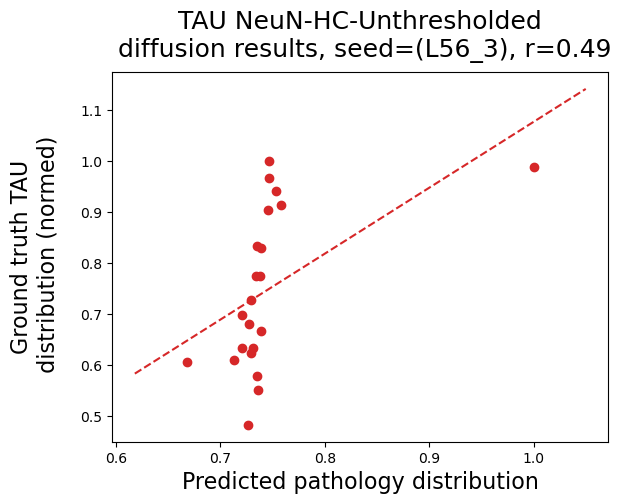

In [33]:
print(report_results(tau_neun_spread, tau_patho_avg, node_atlas))
print(node_atlas[report_results(tau_neun_spread, tau_patho_avg, node_atlas)[0]])
plot_diffusion_result(tau_neun_spread, tau_patho_avg, group='TAU NeuN-HC-Unthresholded\n', color_scatter = 'tab:red', color_line = 'tab:red')

### a.ii. Tau diffusion through SMI32

In [34]:
tau_smi32_spread = optimize_spread(HC_SMI32_network, 
                                    tau_patho_avg, 
                                    seeds=range(len(node_atlas)), 
                                    B=0.01, 
                                    t_iter=1000, 
                                    t_step=1, 
                                    optim_metric='SSE', 
                                    normalize_net=False,
                                    normalize_dist=True
                                    )

(15, 29, {'slope': 0.6401286022761493, 'int': -0.004990328477193547, 'pearsonr': 0.5008993999390768, 'p_val': 0.01756986365271674, 'std_err': 0.24732701815593475, 'SSE': 0.38684324941129905})
L56_5


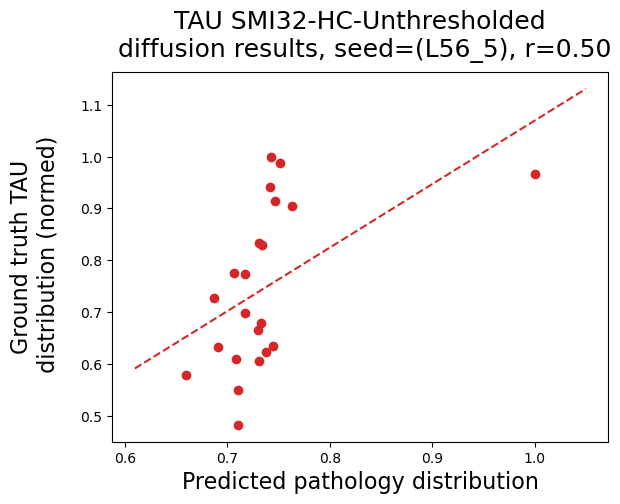

In [35]:
print(report_results(tau_smi32_spread, tau_patho_avg, node_atlas))
print(node_atlas[report_results(tau_smi32_spread, tau_patho_avg, node_atlas)[0]])
plot_diffusion_result(tau_smi32_spread, tau_patho_avg, group='TAU SMI32-HC-Unthresholded\n', color_scatter = 'tab:red', color_line = 'tab:red')

### b.i. TDP43 diffusion through NeuN

In [36]:
tdp43_neun_spread = optimize_spread(HC_NeuN_network, 
                                    tdp_patho_avg, 
                                    seeds=range(len(node_atlas)), 
                                    B=0.001, 
                                    t_iter=1000, 
                                    t_step=1, 
                                    optim_metric='SSE', 
                                    normalize_net=False,
                                    normalize_dist=True
                                    )

(0, 261, {'slope': 0.06821327626547691, 'int': -0.00024708518752730767, 'pearsonr': 0.6607286087532915, 'p_val': 0.0008160226180958143, 'std_err': 0.017328212015747912, 'SSE': 0.365428046582626})
L23_1


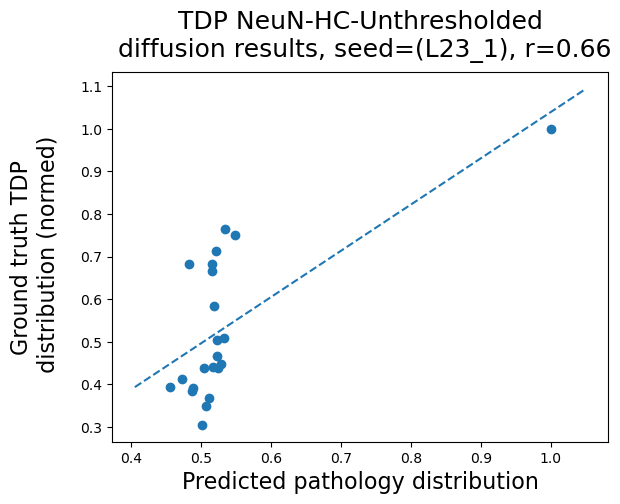

In [37]:
print(report_results(tdp43_neun_spread, tdp_patho_avg, node_atlas))
print(node_atlas[report_results(tdp43_neun_spread, tdp_patho_avg, node_atlas)[0]])
plot_diffusion_result(tdp43_neun_spread, tdp_patho_avg, group='TDP NeuN-HC-Unthresholded\n', color_scatter = 'C0', color_line = 'C0')

### b.ii. TDP43 diffusion through SMI32

In [38]:
tdp43_smi32_spread = optimize_spread(HC_SMI32_network, 
                                    tdp_patho_avg, 
                                    seeds=range(len(node_atlas)), 
                                    B=0.001, 
                                    t_iter=1000, 
                                    t_step=1, 
                                    optim_metric='SSE', 
                                    normalize_net=False,
                                    normalize_dist=True
                                    )

(0, 280, {'slope': 0.06530192708707439, 'int': -0.000114751133963557, 'pearsonr': 0.6378787221706482, 'p_val': 0.0014036806493813038, 'std_err': 0.017629531731008338, 'SSE': 0.3833348728369488})
L23_1


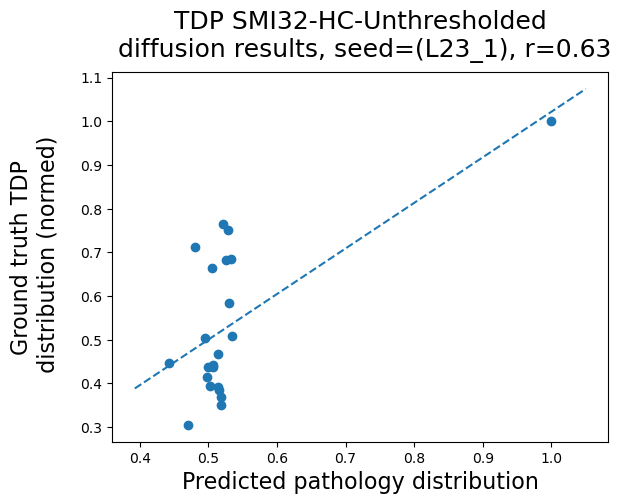

In [44]:
print(report_results(tdp43_smi32_spread, tdp_patho_avg, node_atlas))
print(node_atlas[tdp43_smi32_spread[0]])
plot_diffusion_result(tdp43_smi32_spread, tdp_patho_avg, group='TDP SMI32-HC-Unthresholded\n', color_scatter = 'C0', color_line = 'C0')

### Thresholding the networks

Using the p-values as a thresholding map.

### Thresholded network diffusion model testing

#### i. Tau with thresholded networks

In [41]:
tau_neun_thresh_spread = optimize_spread(HC_NeuN_sig_network, 
                                        tau_patho_avg, 
                                        seeds=range(len(node_atlas)), 
                                        B=0.001, 
                                        t_iter=1000, 
                                        t_step=1, 
                                        optim_metric='SSE', 
                                        normalize_net=False,
                                        normalize_dist=True
                                        )

(13, 578, {'slope': 0.5968376810111827, 'int': -0.003022559328785975, 'pearsonr': 0.7339527946587525, 'p_val': 0.00010108113248907492, 'std_err': 0.12350117616283186, 'SSE': 0.2378923739683578})
L56_3


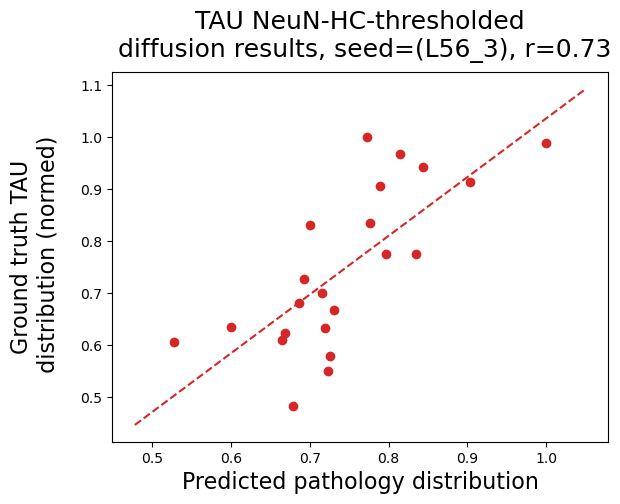

In [42]:
print(report_results(tau_neun_thresh_spread, tau_patho_avg, node_atlas))
print(node_atlas[tau_neun_thresh_spread[0]])
plot_diffusion_result(tau_neun_thresh_spread, tau_patho_avg, group='TAU NeuN-HC-thresholded\n', color_scatter = 'tab:red', color_line = 'tab:red')

In [45]:
tau_smi32_thresh_spread = optimize_spread(HC_SMI32_sig_network, 
                                        tau_patho_avg, 
                                        seeds=range(len(node_atlas)), 
                                        B=0.001, 
                                        t_iter=1000, 
                                        t_step=1, 
                                        optim_metric='SSE', 
                                        normalize_net=False,
                                        normalize_dist=True
                                        )

L56_5


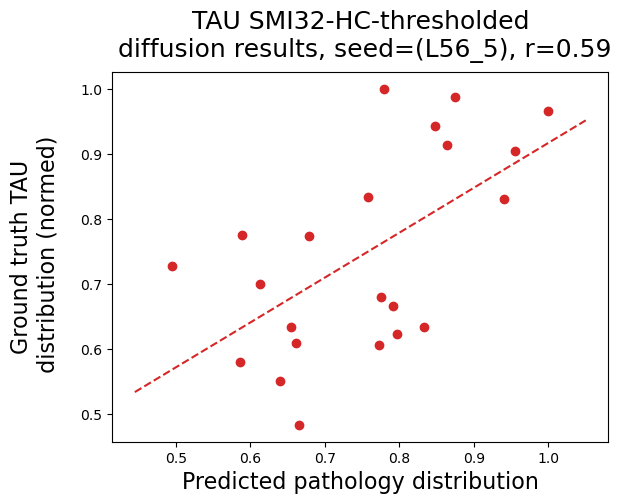

In [46]:
report_results(tau_smi32_thresh_spread, tau_patho_avg, node_atlas)
print(node_atlas[tau_smi32_thresh_spread[0]])
plot_diffusion_result(tau_smi32_thresh_spread, tau_patho_avg, group='TAU SMI32-HC-thresholded\n', color_scatter = 'tab:red', color_line = 'tab:red')

#### ii.a. TDP with thresholded networks

In [47]:
tdp_neun_thresh_spread = optimize_spread(HC_NeuN_sig_network, 
                                        tdp_patho_avg, 
                                        seeds=range(len(node_atlas)), 
                                        B=0.001, 
                                        t_iter=1000, 
                                        t_step=1, 
                                        optim_metric='SSE', 
                                        normalize_net=False,
                                        normalize_dist=True
                                        )

L23_1


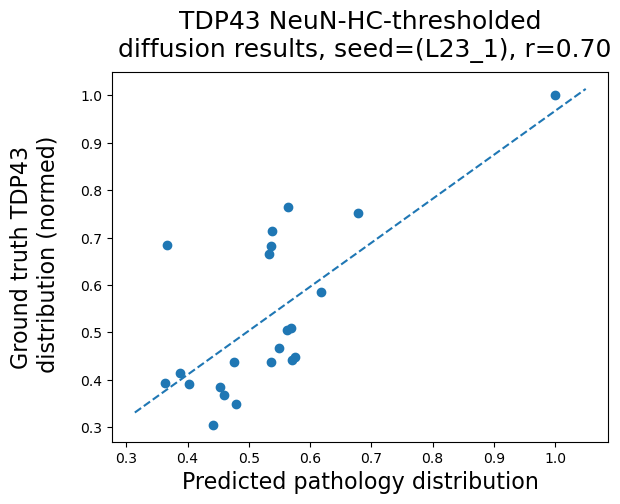

In [48]:
report_results(tdp_neun_thresh_spread, tdp_patho_avg, node_atlas)
print(node_atlas[tdp_neun_thresh_spread[0]])
plot_diffusion_result(tdp_neun_thresh_spread, tdp_patho_avg, group='TDP43 NeuN-HC-thresholded\n', color_scatter = 'C0', color_line = 'C0')

In [49]:
tdp_smi32_thresh_spread = optimize_spread(HC_SMI32_sig_network, 
                                        tdp_patho_avg, 
                                        seeds=range(len(node_atlas)), 
                                        B=0.001, 
                                        t_iter=1000, 
                                        t_step=1, 
                                        optim_metric='SSE', 
                                        normalize_net=False,
                                        normalize_dist=True
                                        )

L23_1


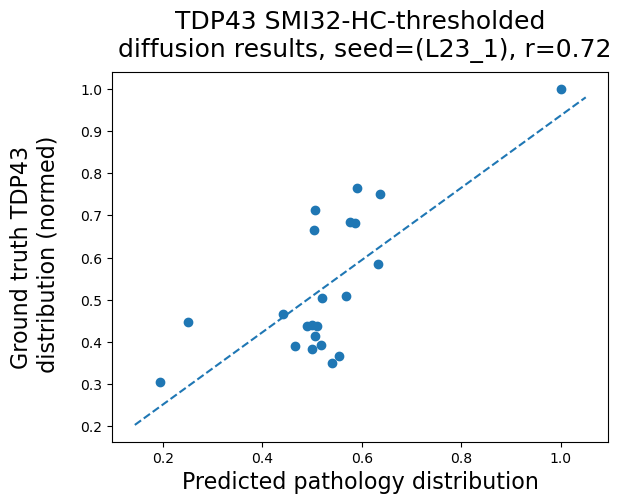

In [50]:
report_results(tdp_smi32_thresh_spread, tdp_patho_avg, node_atlas)
print(node_atlas[tdp_smi32_thresh_spread[0]])
plot_diffusion_result(tdp_smi32_thresh_spread, tdp_patho_avg, group='TDP43 SMI32-HC-thresholded\n', color_scatter = 'C0', color_line = 'C0')

In [51]:
atlas_vec = np.array(node_atlas)

node_result_table = pd.DataFrame(atlas_vec, columns=['Node (layer_subroi)'])

node_result_table['Tau-groundtruth'] = tau_patho_avg/np.sum(tau_patho_avg)
node_result_table['Tau-HCNeuN_Thresh'] = tau_neun_thresh_spread[2]/np.sum(tau_neun_thresh_spread[2])
node_result_table['Tau-HCSMI32_Thresh'] = tau_smi32_thresh_spread[2]/np.sum(tau_smi32_thresh_spread[2])
node_result_table['TDP-groundtruth'] = tdp_patho_avg/np.sum(tdp_patho_avg)
node_result_table['TDP-HCNeuN_Thresh'] = tdp_neun_thresh_spread[2]/np.sum(tdp_neun_thresh_spread[2])
node_result_table['TDP-HCSMI32_Thresh'] = tdp_smi32_thresh_spread[2]/np.sum(tdp_smi32_thresh_spread[2])

node_result_table

,Node (layer_subroi),Tau-groundtruth,Tau-HCNeuN_Thresh,Tau-HCSMI32_Thresh,TDP-groundtruth,TDP-HCNeuN_Thresh,TDP-HCSMI32_Thresh
0,L23_1,0.042570,0.043729,0.036952,0.085509,0.085764,0.086287
1,L23_2,0.047220,0.051044,0.035528,0.064213,0.058151,0.055014
2,L23_3,0.047144,0.048712,0.040995,0.049962,0.053011,0.054533
3,L23_4,0.050785,0.047435,0.045722,0.043499,0.048845,0.048951
4,L23_5,0.055115,0.048192,0.057661,0.039919,0.047118,0.038166
5,L23_6,0.033529,0.044169,0.038636,0.065412,0.048397,0.050937
6,L23_7,0.037112,0.040650,0.039938,0.058388,0.046027,0.050559
7,L23_8,0.035285,0.044364,0.035332,0.060995,0.046081,0.043726
8,L23_9,0.038557,0.043954,0.039499,0.056865,0.045697,0.043551
9,L23_10,0.029392,0.041452,0.040110,0.043149,0.048216,0.044844


In [52]:
node_result_table[node_result_table.columns[1:]].sum(axis=0)

Tau-groundtruth       1.0
Tau-HCNeuN_Thresh     1.0
Tau-HCSMI32_Thresh    1.0
TDP-groundtruth       1.0
TDP-HCNeuN_Thresh     1.0
TDP-HCSMI32_Thresh    1.0
dtype: float64

In [90]:
node_result_table.to_csv('laminar_network_diffusion_optimal-102226.csv', index=None)

# Random testing

To test the significance of using laminar covariance networks, we randomly shuffle the network edges to create random null model networks. The null hypothesis would thus be that the laminar covariance networks and random null model networks offer the same performance. If this null is rejected by the permutation test, then the laminar covariance networks offer a significant contribution to the model performance.

## i. Randomize the HC networks 

In [53]:
# Randomize connectome and plot
def random_null_network(net, seed):
    n = net.shape[0]
    # Get indices and values of the upper triangular of the adjacency matrix
    upper_inds = np.triu_indices(n, k=1)
    upper_vals = net[upper_inds]
    # Shuffle the values
    rng = np.random.default_rng(seed)
    rng.shuffle(upper_vals)
    # Create a new adjacency matrix with shuffled values
    random_net = np.zeros_like(net)
    random_net[upper_inds] = upper_vals
    # Add the transpose to fill lower triangular
    random_net = random_net + random_net.transpose()
    return random_net

### Create 100 random networks from NeuN and SMI32 HC networks

In [149]:
neun_hc_random = []
smi32_hc_random = []

num_random_nets = 1000 #100

for i in range(num_random_nets):
    neun_hc_random.append(random_null_network(HC_NeuN_sig_network, i))
    smi32_hc_random.append(random_null_network(HC_SMI32_sig_network, i))
    

### i.a. Estimating pathology with diffusion through random HC networks

In [150]:
def run_random_nets(random_nets, patho_avg):
    random_net_perf = []
    for i in range(len(random_nets)):
        random_spread = optimize_spread(random_nets[i], 
                                        patho_avg, 
                                        seeds=range(len(node_atlas)), 
                                        B=0.001, 
                                        t_iter=1000, 
                                        t_step=10, 
                                        optim_metric='SSE', 
                                        normalize_net=False,
                                        normalize_dist=True
                                        )

        seed, time, performance = report_results(random_spread, patho_avg, node_atlas, return_res=True)
        random_net_perf.append([seed, time, performance['pearsonr'], performance['p_val'], performance['std_err'], performance['SSE']])
        
    random_net_perf_df = pd.DataFrame(random_net_perf, columns=['seed','time','pearsonr','p_val','std_err','SSE'])
    return random_net_perf_df

In [151]:
neunHC_random_TAU_df = run_random_nets(neun_hc_random, tau_patho_avg)
neunHC_random_TDP_df = run_random_nets(neun_hc_random, tdp_patho_avg)
smi32HC_random_TAU_df = run_random_nets(smi32_hc_random, tau_patho_avg)
smi32HC_random_TDP_df = run_random_nets(smi32_hc_random, tdp_patho_avg)

In [198]:
def plot_random_results(random_df, group, color, real_net_results, real_patho_avg, title=True, minmax_lims=False, minmax_data=None):
    real_seed, real_t, real_perf = report_results(real_net_results, real_patho_avg, node_atlas, return_res=True)
    real_p = real_perf['p_val']
    real_r = real_perf['pearsonr']
    print(real_perf)
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(7,2.5), dpi=300)
    
    plt.subplots_adjust(hspace=0.7)
    
    if minmax_lims:
        axes[0].set_xlim(minmax_data['r_xlim'])
        axes[0].set_ylim(minmax_data['freq_ylim'])
        axes[1].set_xlim(minmax_data['logp_xlim'])
        axes[1].set_ylim(minmax_data['freq_ylim'])


    offset = np.floor(minmax_data['freq_ylim'][1] * 0.03)
    
    rcounts, _ , _ = axes[0].hist(random_df['pearsonr'], color=color)
    axes[0].vlines(x=real_r, ymin=0, ymax=minmax_data['freq_ylim'][1]-offset, color='C1', linestyles='dashed')
    axes[0].set_xlabel("Pearson's R")
    axes[0].set_ylabel("Frequency")

    print(real_r)
    if title:
        axes[0].set_title(group + ' Pearson R distr.')

    pcounts, _, _ = axes[1].hist(np.log10(random_df['p_val']), color=color)
    axes[1].vlines(x=np.log10(real_p), ymin=0, ymax=minmax_data['freq_ylim'][1]-offset, color='C1', linestyles='dashed')
    axes[1].set_xlabel("log10 p-value")
    print(real_p)

    axes[1].vlines(x=np.log10(0.05), ymin=0, ymax=minmax_data['freq_ylim'][1]-offset, color='black', linestyles='dashed')
    axes[1].text(-1.25, minmax_data['freq_ylim'][1]-offset*2, 'p=0.05', fontsize=8, color='black')
    if title:
        axes[1].set_title(group + ' log p-value distr.')

### Standardizing the plots

- Standardize the range of each axis
    - For all y axes, standardize the values
    - For Pearson r axes, min-max all ranges to 0-1 
    - For log10 p-value axes, change to the min and max based on both groups 


In [199]:
# I set the min/max manually
minmax_data = {'r_xlim':[0,1],
               'logp_xlim':[-5,0],
               'freq_ylim':[0,350]}

{'slope': 0.5968376810111827, 'int': -0.003022559328785975, 'pearsonr': 0.7339527946587525, 'p_val': 0.00010108113248907492, 'std_err': 0.12350117616283186, 'SSE': 0.2378923739683578}
0.7339527946587525
0.00010108113248907492


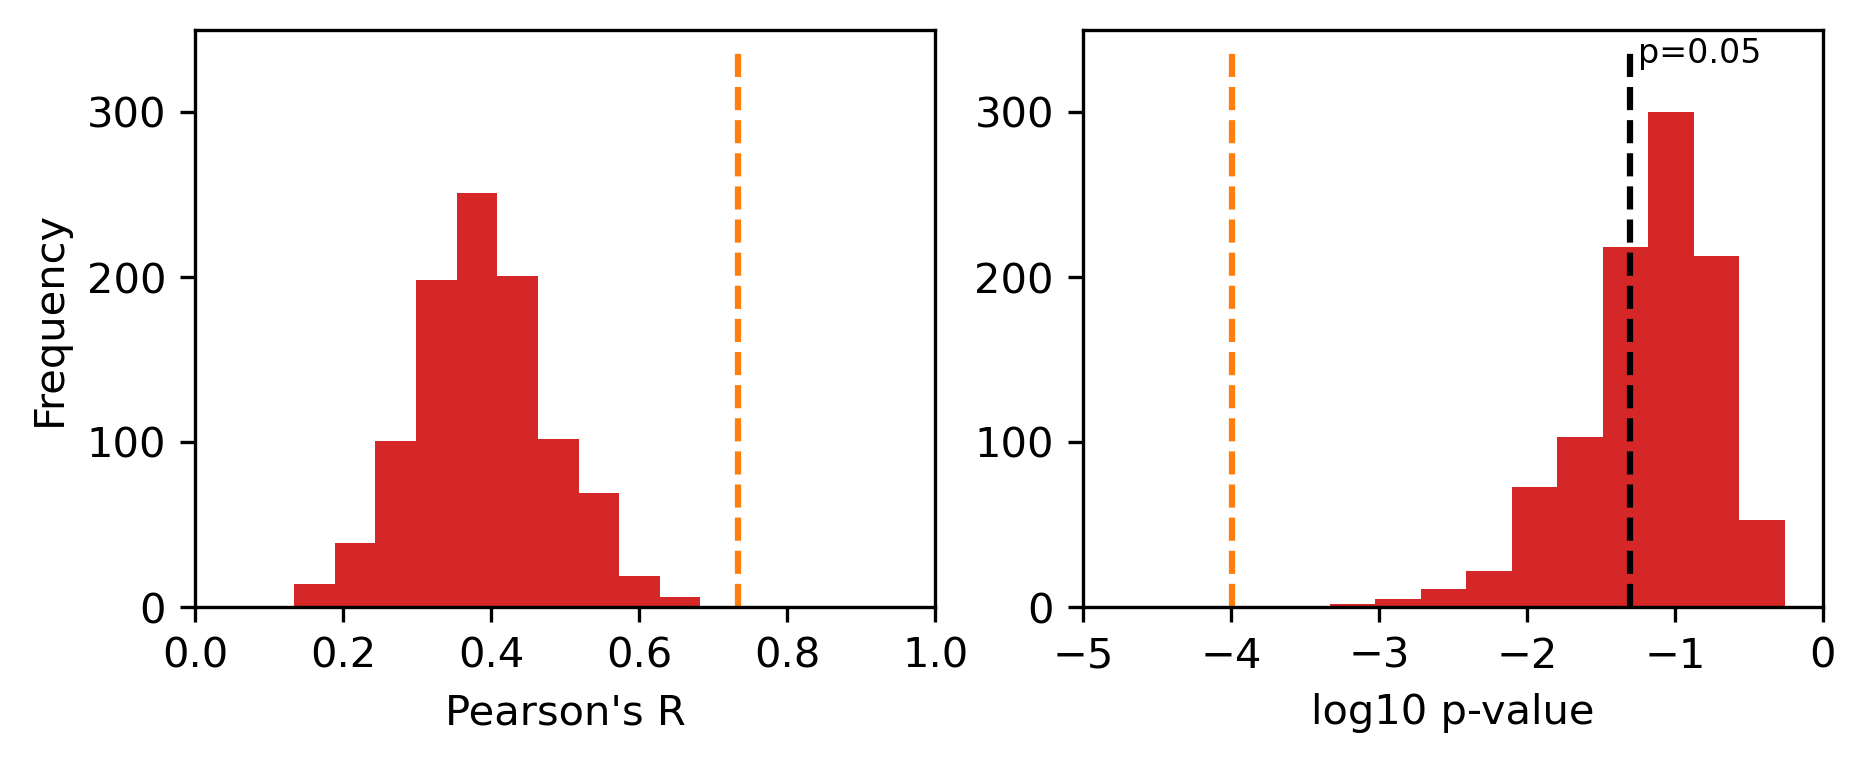

In [200]:
plot_random_results(neunHC_random_TAU_df, "Tau, random HC NeuN\n", 'tab:red', tau_neun_thresh_spread, tau_patho_avg, title=False, minmax_lims=True, minmax_data=minmax_data)

{'slope': 0.37015797155733543, 'int': 0.007281063828207087, 'pearsonr': 0.5904251677523348, 'p_val': 0.0038173080114336823, 'std_err': 0.11314373154882329, 'SSE': 0.36688670847313676}
0.5904251677523348
0.0038173080114336823


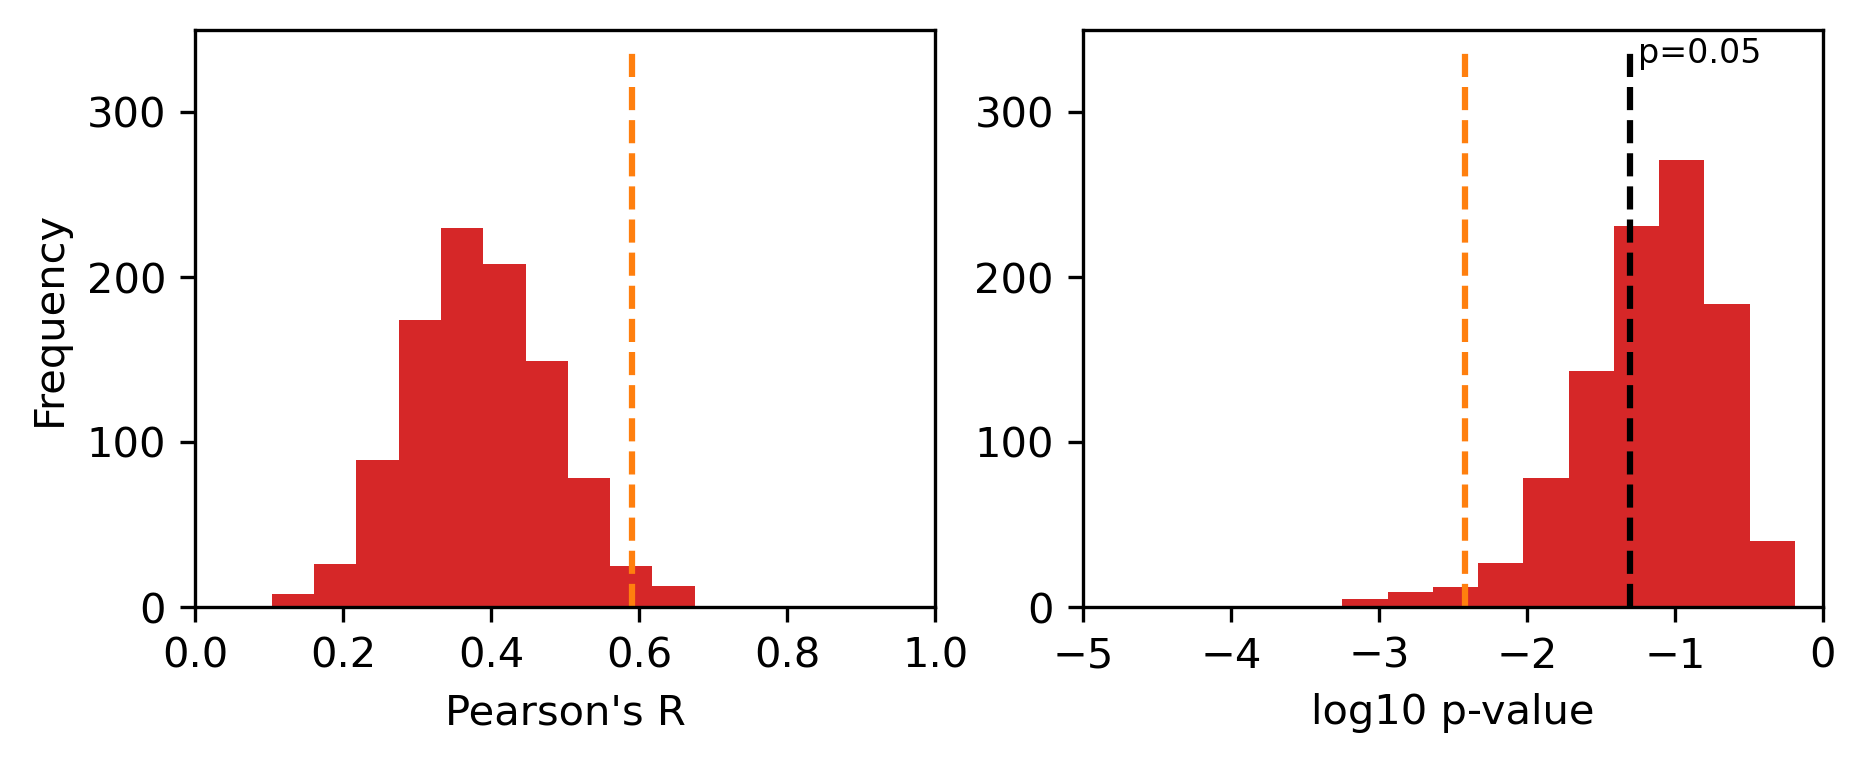

In [201]:
plot_random_results(smi32HC_random_TAU_df, "Tau, random HC SMI32\n", 'tab:red', tau_smi32_thresh_spread, tau_patho_avg, title=False, minmax_lims=True, minmax_data=minmax_data)

{'slope': 0.05802345749235894, 'int': 0.00021608839306896336, 'pearsonr': 0.705863825113941, 'p_val': 0.00024213886135850265, 'std_err': 0.01302009283274275, 'SSE': 0.3259152489741014}
0.705863825113941
0.00024213886135850265


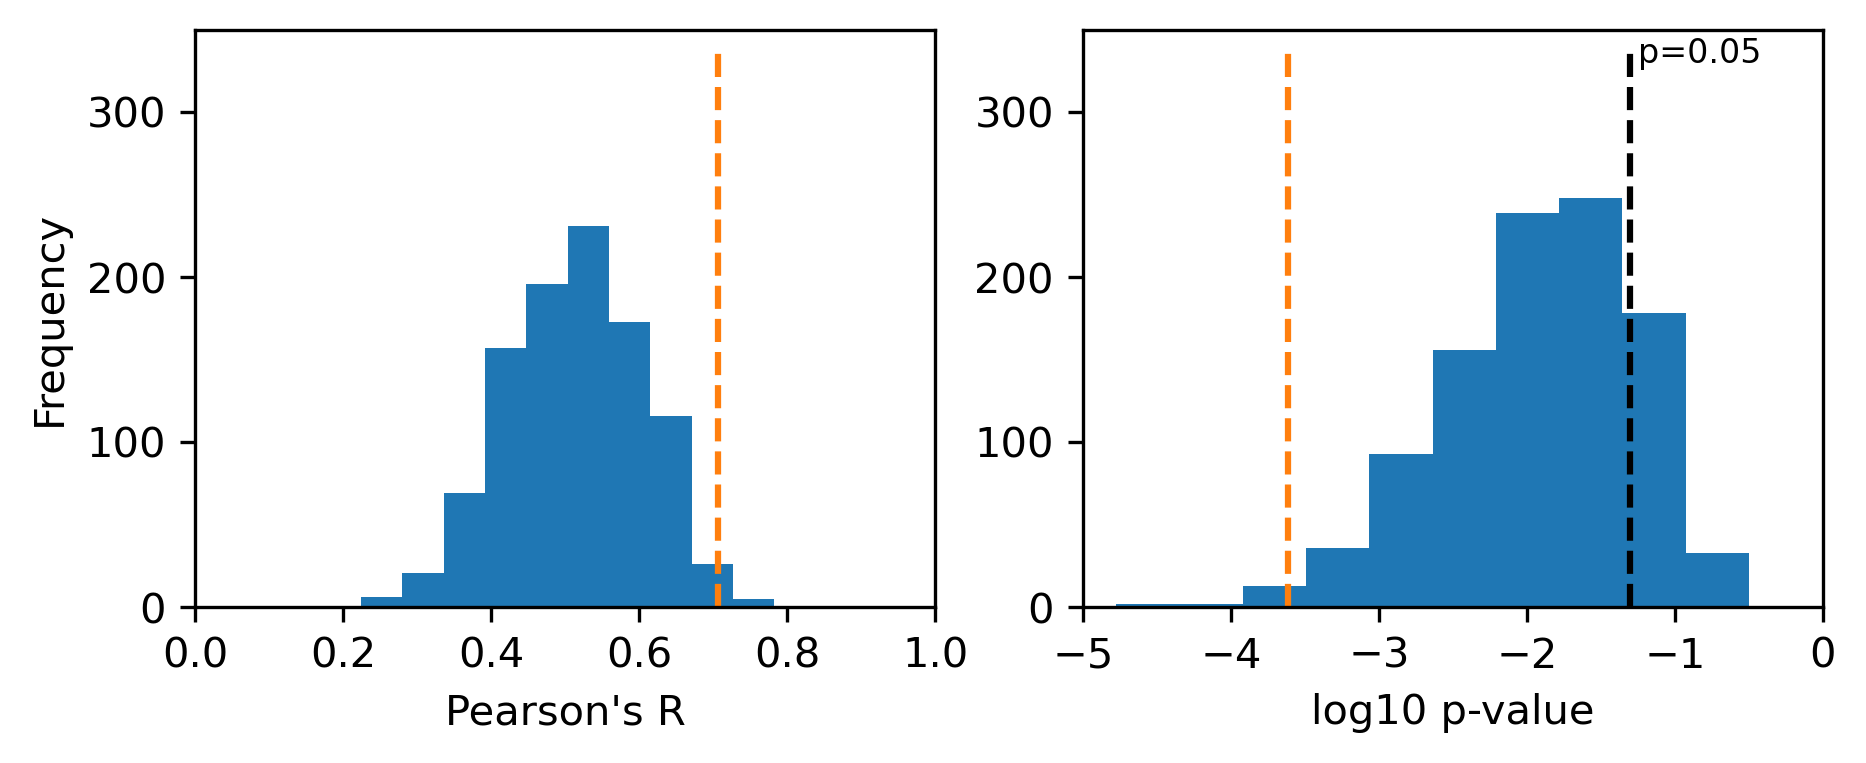

In [202]:
plot_random_results(neunHC_random_TDP_df, "TDP, random HC NeuN\n", 'C0', tdp_neun_thresh_spread, tdp_patho_avg, title=False, minmax_lims=True, minmax_data=minmax_data)

{'slope': 0.053328115390470145, 'int': 0.00042951303406390867, 'pearsonr': 0.7255913908460038, 'p_val': 0.00013253096519138402, 'std_err': 0.011308811522787326, 'SSE': 0.3155752532898341}
0.7255913908460038
0.00013253096519138402


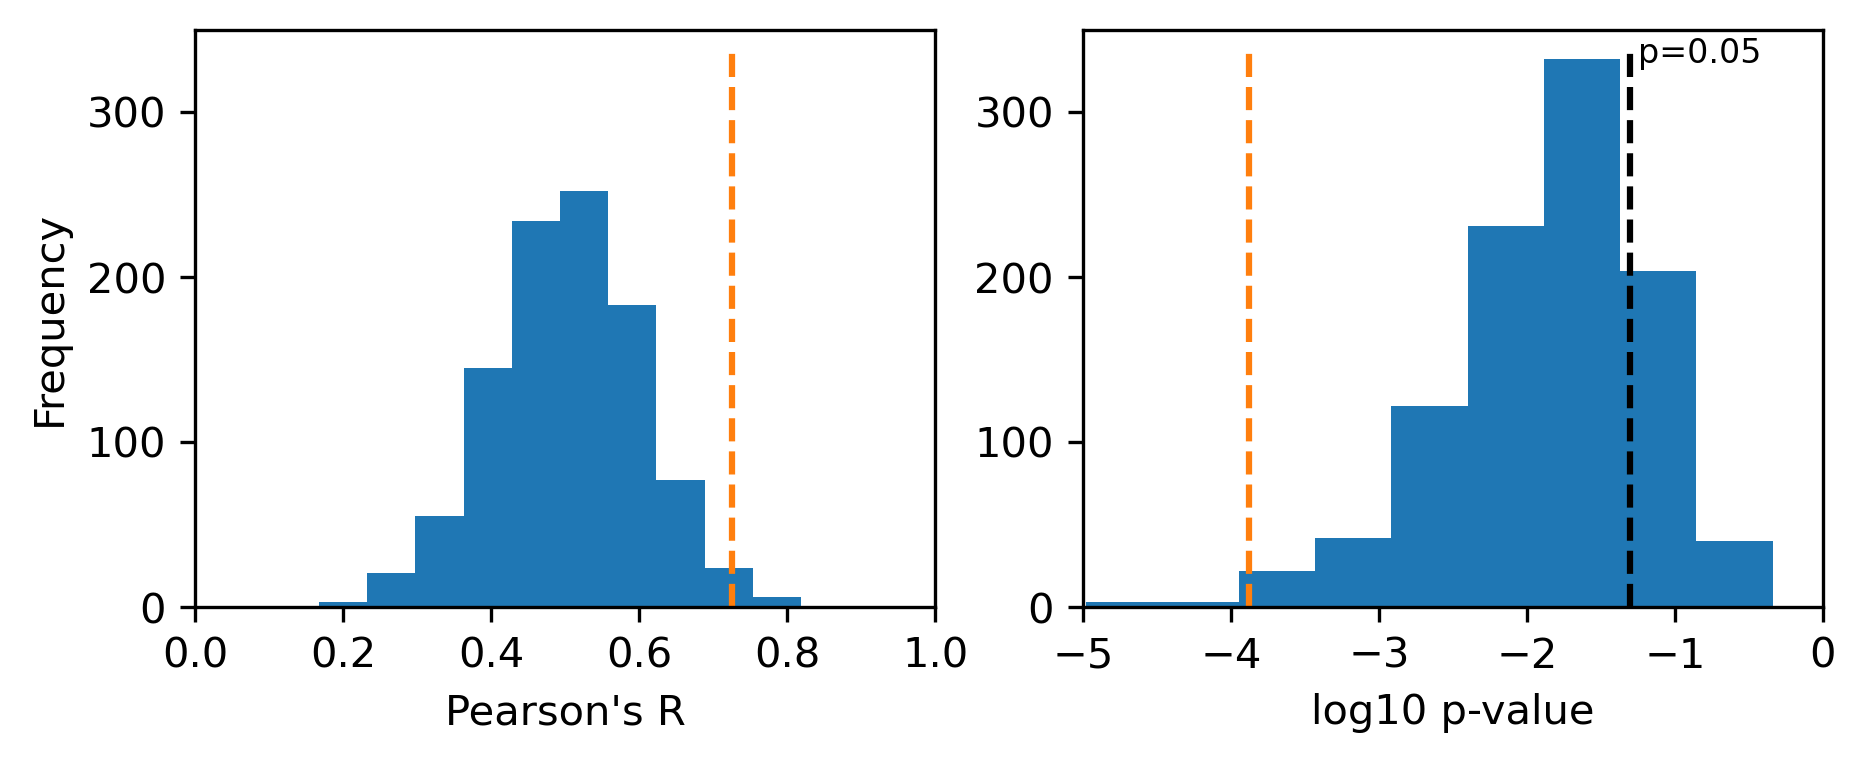

In [203]:
plot_random_results(smi32HC_random_TDP_df, "TDP, random HC SMI32\n", 'C0', tdp_smi32_thresh_spread, tdp_patho_avg, title=False, minmax_lims=True, minmax_data=minmax_data)

### Empirical p-value

To reject or accept the null, compute an empirical $P$-value with a pseudocount adjustment. This counts the number of times a randomly null model performance Pearson's $R$ exceeds the actual model's Pearson's $R$. 

$$\text{empirical} P = \frac{\sum (R_{\text{perm}} \ge R_{\text{obs}}) + 1}{N+1}$$


In [158]:
def empirical_p(result, permutation_results, perform_better='geq', bias_correction=False):
    # Either less than or equal to, or greater than or equal to.
    # If the target metric is "greater is better" i.e. Pearson's correlation, set to 'geq'.
    # If the target metric is "less is better" i.e. log P-val, set to 'leq'.
    if perform_better == 'leq':
        outperformance_count = np.sum(permutation_results <= result)
    else:
        outperformance_count = np.sum(permutation_results >= result)
    
    # Formula for the empirical p-value
    if bias_correction:
        return (outperformance_count+1)/(len(permutation_results)+1)
    if not bias_correction:
        return (outperformance_count)/(len(permutation_results))

In [159]:
# Wrapper function to grab the necessary data from the other data structures and compute the empirical p
def compute_empirical_p_wrapper(random_df, real_net_results, real_patho_avg):
    _, _, real_perf = report_results(real_net_results, real_patho_avg, node_atlas, return_res=True)
    real_r = real_perf['pearsonr']
    #real_p = real_perf['p_val']
    random_r = random_df['pearsonr']
    #random_p = random_df['p_val']

    # Set bias correction to True
    pearsonr_emp_p = empirical_p(real_r, random_r, perform_better='geq', bias_correction=True)
    #pval_emp_p = empirical_p(real_p, random_p, perform_better='leq', bias_correction=True)
    
    return pearsonr_emp_p#, pval_emp_p

In [207]:
empirical_p_results = []
empirical_p_results.append(['Tau','NeuN'] + [compute_empirical_p_wrapper(neunHC_random_TAU_df, tau_neun_thresh_spread, tau_patho_avg)])
empirical_p_results.append(['Tau','SMI32'] + [compute_empirical_p_wrapper(smi32HC_random_TAU_df, tau_smi32_thresh_spread, tau_patho_avg)])
empirical_p_results.append(['TDP','NeuN'] + [compute_empirical_p_wrapper(neunHC_random_TDP_df, tdp_neun_thresh_spread, tdp_patho_avg)])
empirical_p_results.append(['TDP','SMI32'] + [compute_empirical_p_wrapper(smi32HC_random_TDP_df, tdp_neun_thresh_spread, tdp_patho_avg)])
empirical_p_results_df = pd.DataFrame(empirical_p_results, columns=['Pathology','Network','R empirical P'])
empirical_p_results_df['R emp. P (FDR)'] = multipletests(empirical_p_results_df['R empirical P'], alpha=0.05, method='fdr_bh')[1]
empirical_p_results_df

,Pathology,Network,R empirical P,R emp. P (FDR)
0,Tau,NeuN,0.000999,0.003996
1,Tau,SMI32,0.020979,0.021978
2,TDP,NeuN,0.010989,0.021978
3,TDP,SMI32,0.021978,0.021978


In [206]:
 multipletests(empirical_p_results_df['R empirical P'], alpha=0.05, method='fdr_bh')

(array([ True,  True,  True,  True]),
 array([0.003996  , 0.02197802, 0.02197802, 0.02197802]),
 0.012741455098566168,
 0.0125)

# Performance with each seed

Test the performance of each seed. This is to see whether specific groups of seeds perform better than others, for example if we can find a pattern of certain regions' upper/lower layers serving as better seeds than others, or patterns along the cortical gradient.

In [88]:
tau_neunHC_thresh_seedres = optimize_spread(HC_NeuN_sig_network, 
                                            tau_patho_avg, 
                                            seeds=range(len(node_atlas)), 
                                            B=0.001, 
                                            t_iter=1000, 
                                            t_step=1, 
                                            optim_metric='SSE', 
                                            normalize_net=False,
                                            normalize_dist=True,
                                            return_all=True
                                            )

In [89]:
tau_smi32HC_thresh_seedres = optimize_spread(HC_SMI32_sig_network, 
                                            tau_patho_avg, 
                                            seeds=range(len(node_atlas)), 
                                            B=0.001, 
                                            t_iter=1000, 
                                            t_step=1, 
                                            optim_metric='SSE', 
                                            normalize_net=False,
                                            normalize_dist=True,
                                            return_all=True
                                            )

In [90]:
tdp_neunHC_thresh_seedres = optimize_spread(HC_NeuN_sig_network, 
                                            tdp_patho_avg, 
                                            seeds=range(len(node_atlas)), 
                                            B=0.001, 
                                            t_iter=1000, 
                                            t_step=1, 
                                            optim_metric='SSE', 
                                            normalize_net=False,
                                            normalize_dist=True,
                                            return_all=True
                                            )

In [91]:
tdp_smi32HC_thresh_seedres = optimize_spread(HC_SMI32_sig_network, 
                                            tdp_patho_avg, 
                                            seeds=range(len(node_atlas)), 
                                            B=0.001, 
                                            t_iter=1000, 
                                            t_step=1, 
                                            optim_metric='SSE', 
                                            normalize_net=False,
                                            normalize_dist=True,
                                            return_all=True
                                            )

In [92]:
# For each seed, for the minimum SSE, query the min along the time axis
# For the corresponding PearsonR, query the argmin of the SSE on the time axis, and index the PearsonR for that seed
# Similarly for the PearsonR pval, do the same as the PearsonR
seed_SSE_results = np.array([[min(seed_sse) for seed_sse in tau_neunHC_thresh_seedres[3]],
                              [seed_r[np.argmin(seed_sse)] for seed_sse, seed_r in zip(tau_neunHC_thresh_seedres[3], tau_neunHC_thresh_seedres[4])],
                              [seed_rp[np.argmin(seed_sse)] for seed_sse, seed_rp in zip(tau_neunHC_thresh_seedres[3], tau_neunHC_thresh_seedres[5])],

                              [min(seed_sse) for seed_sse in tau_smi32HC_thresh_seedres[3]],
                              [seed_r[np.argmin(seed_sse)] for seed_sse, seed_r in zip(tau_smi32HC_thresh_seedres[3], tau_smi32HC_thresh_seedres[4])],
                              [seed_rp[np.argmin(seed_sse)] for seed_sse, seed_rp in zip(tau_smi32HC_thresh_seedres[3], tau_smi32HC_thresh_seedres[5])],
                             
                              [min(seed_sse) for seed_sse in tdp_neunHC_thresh_seedres[3]],
                              [seed_r[np.argmin(seed_sse)] for seed_sse, seed_r in zip(tdp_neunHC_thresh_seedres[3], tdp_neunHC_thresh_seedres[4])],
                              [seed_rp[np.argmin(seed_sse)] for seed_sse, seed_rp in zip(tdp_neunHC_thresh_seedres[3], tdp_neunHC_thresh_seedres[5])],
                             
                              [min(seed_sse) for seed_sse in tdp_smi32HC_thresh_seedres[3]],
                              [seed_r[np.argmin(seed_sse)] for seed_sse, seed_r in zip(tdp_smi32HC_thresh_seedres[3], tdp_smi32HC_thresh_seedres[4])],
                              [seed_rp[np.argmin(seed_sse)] for seed_sse, seed_rp in zip(tdp_smi32HC_thresh_seedres[3], tdp_smi32HC_thresh_seedres[5])]]
                              ).transpose()


In [93]:
node_atlas_items = np.array([node.split('_') for node in node_atlas])
print(node_atlas_items.transpose())

[['L23' 'L23' 'L23' 'L23' 'L23' 'L23' 'L23' 'L23' 'L23' 'L23' 'L23' 'L56'
  'L56' 'L56' 'L56' 'L56' 'L56' 'L56' 'L56' 'L56' 'L56' 'L56']
 ['1' '2' '3' '4' '5' '6' '7' '8' '9' '10' '11' '1' '2' '3' '4' '5' '6'
  '7' '8' '9' '10' '11']]


In [94]:
seed_SSE_results_df = pd.DataFrame(seed_SSE_results, columns=['Tau_HCNeuN_SSE', 'Tau_HCNeuN_R', 'Tau_HCNeuN_R_pval', 
                                                              'Tau_HCSMI32_SSE', 'Tau_HCSMI32_R', 'Tau_HCSMI32_R_pval', 
                                                              'TDP_HCNeuN_SSE', 'TDP_HCNeuN_R', 'TDP_HCNeuN_R_pval', 
                                                              'TDP_HCSMI32_SSE', 'TDP_HCSMI32_R', 'TDP_HCSMI32_R_pval'])
seed_SSE_results_df.insert(0,'subROI_ID', np.array(node_atlas_items).transpose()[1].astype(int))
seed_SSE_results_df.insert(1,'Layer', np.array(node_atlas_items).transpose()[0])
seed_SSE_results_df.insert(2,'Node (layer_subROI)',node_atlas)


In [95]:
seed_SSE_results_df

,subROI_ID,Layer,Node (layer_subROI),Tau_HCNeuN_SSE,Tau_HCNeuN_R,Tau_HCNeuN_R_pval,Tau_HCSMI32_SSE,Tau_HCSMI32_R,Tau_HCSMI32_R_pval,TDP_HCNeuN_SSE,TDP_HCNeuN_R,TDP_HCNeuN_R_pval,TDP_HCSMI32_SSE,TDP_HCSMI32_R,TDP_HCSMI32_R_pval
0,1,L23,L23_1,0.711902,-0.095011,0.674059,0.921128,-0.159850,0.477339,0.325915,0.705864,0.000242,0.315575,0.725591,0.000133
1,2,L23,L23_2,0.464517,0.336487,0.125724,1.095228,-0.266467,0.230640,0.590265,0.425982,0.048071,0.454577,0.616885,0.002228
2,3,L23,L23_3,0.552802,0.133552,0.553507,0.766678,0.088532,0.695220,0.684514,0.299246,0.176087,0.791938,0.311513,0.158174
3,4,L23,L23_4,0.437301,0.442160,0.039357,1.128454,-0.007763,0.972647,0.806793,0.225694,0.312537,0.901732,0.256781,0.248673
4,5,L23,L23_5,0.319181,0.622454,0.001977,0.631267,0.347225,0.113357,0.998151,0.075882,0.737154,1.045780,-0.073261,0.745935
5,6,L23,L23_6,1.219873,-0.643686,0.001228,1.404128,-0.450217,0.035505,0.721456,0.328078,0.136062,0.560199,0.555730,0.007246
6,7,L23,L23_7,1.176205,-0.714356,0.000188,1.509006,-0.366612,0.093308,1.145033,0.005838,0.979429,0.645597,0.524039,0.012301
7,8,L23,L23_8,1.047522,-0.586620,0.004109,1.173211,-0.449532,0.035821,0.867125,0.113535,0.614912,0.632585,0.468195,0.027980
8,9,L23,L23_9,1.104178,-0.393907,0.069696,1.359673,-0.569795,0.005635,1.137915,-0.019361,0.931850,0.867863,0.310053,0.160236
9,10,L23,L23_10,1.044403,-0.462426,0.030242,1.397644,-0.390416,0.072432,1.192537,-0.045367,0.841113,0.923537,0.307116,0.164441


In [96]:
seed_SSE_results_tau_neunHC = np.array([[min(seed_sse) for seed_sse in tau_neunHC_thresh_seedres[3]],
                                          [seed_r[np.argmin(seed_sse)] for seed_sse, seed_r in zip(tau_neunHC_thresh_seedres[3], tau_neunHC_thresh_seedres[4])],
                                          [seed_rp[np.argmin(seed_sse)] for seed_sse, seed_rp in zip(tau_neunHC_thresh_seedres[3], tau_neunHC_thresh_seedres[5])]]
                                      ).transpose()

seed_SSE_results_tau_smi32HC = np.array([[min(seed_sse) for seed_sse in tau_smi32HC_thresh_seedres[3]],
                                          [seed_r[np.argmin(seed_sse)] for seed_sse, seed_r in zip(tau_smi32HC_thresh_seedres[3], tau_smi32HC_thresh_seedres[4])],
                                          [seed_rp[np.argmin(seed_sse)] for seed_sse, seed_rp in zip(tau_smi32HC_thresh_seedres[3], tau_smi32HC_thresh_seedres[5])]]
                                         ).transpose()

seed_SSE_results_tdp_neunHC = np.array([[min(seed_sse) for seed_sse in tdp_neunHC_thresh_seedres[3]],
                                          [seed_r[np.argmin(seed_sse)] for seed_sse, seed_r in zip(tdp_neunHC_thresh_seedres[3], tdp_neunHC_thresh_seedres[4])],
                                          [seed_rp[np.argmin(seed_sse)] for seed_sse, seed_rp in zip(tdp_neunHC_thresh_seedres[3], tdp_neunHC_thresh_seedres[5])]]
                                         ).transpose()
                                         
seed_SSE_results_tdp_smi32HC = np.array([[min(seed_sse) for seed_sse in tdp_smi32HC_thresh_seedres[3]],
                                          [seed_r[np.argmin(seed_sse)] for seed_sse, seed_r in zip(tdp_smi32HC_thresh_seedres[3], tdp_smi32HC_thresh_seedres[4])],
                                          [seed_rp[np.argmin(seed_sse)] for seed_sse, seed_rp in zip(tdp_smi32HC_thresh_seedres[3], tdp_smi32HC_thresh_seedres[5])]]
                                          ).transpose()


In [97]:
def seed_result_report_df(seed_SSE_results, column_names):
    seed_SSE_results_df = pd.DataFrame(seed_SSE_results, columns=[column_names])
    seed_SSE_results_df.insert(0,'subROI_ID', np.array(node_atlas_items).transpose()[1])
    seed_SSE_results_df.insert(1,'Layer', np.array(node_atlas_items).transpose()[0])
    seed_SSE_results_df.insert(2,'Node [layer_subROI]',node_atlas)
    print(seed_SSE_results_df)
    return seed_SSE_results_df

In [98]:
tau_neunHC_result_df = seed_result_report_df(seed_SSE_results_tau_neunHC, column_names = ['SSE', 'R', 'R_pval'])
tau_smi32HC_result_df = seed_result_report_df(seed_SSE_results_tau_smi32HC, column_names = ['SSE', 'R', 'R_pval'])
tdp_neunHC_result_df = seed_result_report_df(seed_SSE_results_tdp_neunHC, column_names = ['SSE', 'R', 'R_pval'])
tdp_smi32HC_result_df = seed_result_report_df(seed_SSE_results_tdp_smi32HC, column_names = ['SSE', 'R', 'R_pval'])

   subROI_ID Layer Node [layer_subROI]       SSE         R    R_pval
0          1   L23               L23_1  0.711902 -0.095011  0.674059
1          2   L23               L23_2  0.464517  0.336487  0.125724
2          3   L23               L23_3  0.552802  0.133552  0.553507
3          4   L23               L23_4  0.437301  0.442160  0.039357
4          5   L23               L23_5  0.319181  0.622454  0.001977
5          6   L23               L23_6  1.219873 -0.643686  0.001228
6          7   L23               L23_7  1.176205 -0.714356  0.000188
7          8   L23               L23_8  1.047522 -0.586620  0.004109
8          9   L23               L23_9  1.104178 -0.393907  0.069696
9         10   L23              L23_10  1.044403 -0.462426  0.030242
10        11   L23              L23_11  0.738596 -0.130638  0.562272
11         1   L56               L56_1  0.356315  0.559213  0.006815
12         2   L56               L56_2  0.375235  0.511476  0.014972
13         3   L56               L

In [84]:
with pd.ExcelWriter('laminar_seed_results_102226.xlsx', engine='openpyxl') as writer:
    tau_neunHC_result_df.to_excel(writer, sheet_name='Tau_HC_NeuN', )#index=None)
    tau_smi32HC_result_df.to_excel(writer, sheet_name='Tau_HC_SMI32',)#index=None)
    tdp_neunHC_result_df.to_excel(writer, sheet_name='TDP_HC_NeuN', )#index=None)
    tdp_smi32HC_result_df.to_excel(writer, sheet_name='TDP_HC_SMI32', )#index=None)

# Load old data

Run a couple experiments using the new and old data to help us understand why the diffusion results changed so much. Test if the HC network is driving the differences of the pathology measures by mixing and matching the new and old data.

Use old HC networks to predict new pathology data, use new HC networks to predict old pathology data, vice versa. 

In [99]:
def full_test(tau_patho_avg, tdp_patho_avg, NeuN_net, SMI32_net):
    tau_neun_spread = optimize_spread(NeuN_net, 
                                        tau_patho_avg, 
                                        seeds=range(len(node_atlas)), 
                                        B=0.001, 
                                        t_iter=1000, 
                                        t_step=1, 
                                        optim_metric='SSE', 
                                        normalize_net=False,
                                        normalize_dist=True
                                        )
    
    tau_smi32_spread = optimize_spread(SMI32_net, 
                                        tau_patho_avg, 
                                        seeds=range(len(node_atlas)), 
                                        B=0.001, 
                                        t_iter=1000, 
                                        t_step=1, 
                                        optim_metric='SSE', 
                                        normalize_net=False,
                                        normalize_dist=True
                                        )

    tdp_neun_spread = optimize_spread(NeuN_net, 
                                        tdp_patho_avg, 
                                        seeds=range(len(node_atlas)), 
                                        B=0.001, 
                                        t_iter=1000, 
                                        t_step=1, 
                                        optim_metric='SSE', 
                                        normalize_net=False,
                                        normalize_dist=True
                                        )

    tdp_smi32_spread = optimize_spread(SMI32_net, 
                                        tdp_patho_avg, 
                                        seeds=range(len(node_atlas)), 
                                        B=0.001, 
                                        t_iter=1000, 
                                        t_step=1, 
                                        optim_metric='SSE', 
                                        normalize_net=False,
                                        normalize_dist=True
                                        )

    return {"Tau_NeuN": tau_neun_spread, 
            "Tau_SMI32": tau_smi32_spread, 
            "TDP_NeuN": tdp_neun_spread, 
            "TDP_SMI32": tdp_smi32_spread}
    

[['L23', 1], ['L56', 1], ['L23', 2], ['L56', 2], ['L23', 3], ['L56', 3], ['L23', 4], ['L56', 4], ['L23', 5], ['L56', 5], ['L23', 6], ['L56', 6], ['L23', 7], ['L56', 7], ['L23', 8], ['L56', 8], ['L23', 9], ['L56', 9], ['L23', 10], ['L56', 10], ['L23', 11], ['L56', 11]]
['L23_1' 'L56_1' 'L23_2' 'L56_2' 'L23_3' 'L56_3' 'L23_4' 'L56_4' 'L23_5'
 'L56_5' 'L23_6' 'L56_6' 'L23_7' 'L56_7' 'L23_8' 'L56_8' 'L23_9' 'L56_9'
 'L23_10' 'L56_10' 'L23_11' 'L56_11']
['L23_1' 'L23_2' 'L23_3' 'L23_4' 'L23_5' 'L23_6' 'L23_7' 'L23_8' 'L23_9'
 'L23_10' 'L23_11' 'L56_1' 'L56_2' 'L56_3' 'L56_4' 'L56_5' 'L56_6' 'L56_7'
 'L56_8' 'L56_9' 'L56_10' 'L56_11']


<Figure size 640x480 with 0 Axes>

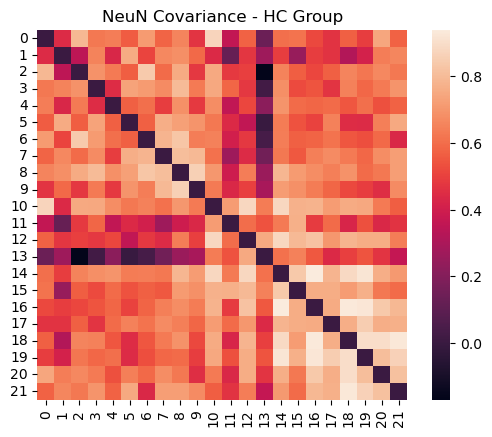

<Figure size 640x480 with 0 Axes>

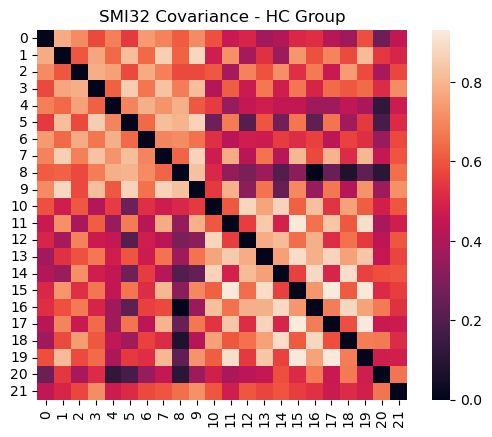

<Figure size 640x480 with 0 Axes>

In [100]:
def parse_neurology_network(neuro_df, type='Original/Raw Values', group='HC', measure='PearsonR'):
    # Generate a list of sub ROIs and source layers
    nodes = []
    
    for subROI in pd.unique(neuro_df['Source_SubROI']):
        for layer in pd.unique(neuro_df['Source_Layer']):
            nodes.append([layer, subROI])

    net = np.zeros((len(nodes), len(nodes)))

    neuro_df_typegroup = neuro_df.loc[(neuro_df['Nodal Type'] == type) &
                                      (neuro_df['Antibody'] == group),:]
    # Populate the adjacency matrix, for every node there is a link to every other node
    for i, from_node in enumerate(nodes):
        for j, to_node in enumerate(nodes):
            # Query the edge entry based on from node and to node ROI and Layer names
            ij_data = neuro_df_typegroup.loc[(neuro_df_typegroup['Source_SubROI'] == from_node[1]) & 
                                             (neuro_df_typegroup['Source_Layer'] == from_node[0]) &
                                             (neuro_df_typegroup['Target_SubROI'] == to_node[1]) & 
                                             (neuro_df_typegroup['Target_Layer'] == to_node[0]), measure]
            
            #If missing, treat as 0, or no edge.
            if ij_data.empty:
                ij_data = 0
            else:
                ij_data = ij_data.item()
            net[i,j] = ij_data

    # The network is upper triangular
    net = net + net.transpose()
    
    return net, nodes
    print(nodes)

neun_conn_df = pd.read_excel("NeuN_Org_ZScore_101625.xlsx")
neun_conn_net_HC, node_atlas_old = parse_neurology_network(neun_conn_df, type='Original/Raw Values', group='HC')

smi32_conn_df = pd.read_excel("SMI32_Org_ZScore_101625.xlsx")
smi32_conn_net_HC, _ = parse_neurology_network(smi32_conn_df, type='Original/Raw Values', group='HC')

print(node_atlas_old)
node_names = np.array([layer + '_' + str(subROI) for layer, subROI in node_atlas_old])
print(node_names)
print(node_atlas)
plt.figure()
sns.heatmap(neun_conn_net_HC, square=True)
plt.title("NeuN Covariance - HC Group")
plt.figure()

plt.figure()
sns.heatmap(smi32_conn_net_HC, square=True)
plt.title("SMI32 Covariance - HC Group")
plt.figure()


In [101]:
neun_conn_pval_HC, _ = parse_neurology_network(neun_conn_df, type='Original/Raw Values', group='HC', measure='pval_corrected')

smi32_conn_pval_HC, _ = parse_neurology_network(smi32_conn_df, type='Original/Raw Values', group='HC', measure='pval_corrected')

HC_NeuN_sig_network_OLD = neun_conn_net_HC * (neun_conn_pval_HC < 0.05)

HC_SMI32_sig_network_OLD = smi32_conn_net_HC * (smi32_conn_pval_HC < 0.05)

In [103]:
def parse_pathology_df(pathology_df, group='TAU'):
    if group == 'TAU':
        antibody = 'AT8'
    if group == 'TDP':
        antibody = 'TDP43'
    print("---- FILTERING FOR " + group + " ----")
    pathology_df_filtered = pathology_df.loc[(pathology_df['Antibody'] == antibody) & (pathology_df['Group'] == group)]

    # Query nodes
    nodes = []
    node_names = []
    for subROI in np.sort(pd.unique(pathology_df_filtered['Subregion#'])):
        for layer in ['L123', 'L456']:
            node_name = subROI
            if layer == 'L123':
                node_name = 'L23_' + str(node_name)
            if layer == 'L456':
                node_name = 'L56_' + str(node_name)
            nodes.append([subROI, layer])
            node_names.append(node_name)
    ids = pd.unique(pathology_df_filtered['AutopsyID'])

    print(node_names)
    
    autopsy_data = []
    for id in ids:
        id_data = []
        for node in nodes:
            id_node_data = pathology_df_filtered.loc[(pathology_df_filtered['AutopsyID'] == id) & 
                                                     (pathology_df_filtered['Subregion#'] == node[0])][node[1]]
            if id_node_data.empty:
                id_node_data = np.nan
            else:
                # If there are more entries, compute the mean
                if len(id_node_data) > 1:
                    id_node_data = np.mean(id_node_data.to_numpy())
                else:
                    id_node_data = id_node_data.item()

            id_data.append(id_node_data)
        autopsy_data.append(id_data)

    autopsy_df = pd.DataFrame(autopsy_data, columns = node_names)
    autopsy_df.insert(0, 'AutopsyID', ids)

    return autopsy_df

pathology_df = pd.read_excel("Neurons_Pathology_HC_TDP_TAU_AD_11subregions_fixed.xlsx")

tau_patho_df = parse_pathology_df(pathology_df, group='TAU')
tdp_patho_df = parse_pathology_df(pathology_df, group='TDP')

tau_patho_avg_OLD = np.nanmean(tau_patho_df[node_names], axis=0)
tdp_patho_avg_OLD = np.nanmean(tdp_patho_df[node_names], axis=0)

print(tau_patho_avg_OLD)
print(tdp_patho_avg_OLD)

---- FILTERING FOR TAU ----
['L23_1', 'L56_1', 'L23_2', 'L56_2', 'L23_3', 'L56_3', 'L23_4', 'L56_4', 'L23_5', 'L56_5', 'L23_6', 'L56_6', 'L23_7', 'L56_7', 'L23_8', 'L56_8', 'L23_9', 'L56_9', 'L23_10', 'L56_10', 'L23_11', 'L56_11']
---- FILTERING FOR TDP ----
['L23_1', 'L56_1', 'L23_2', 'L56_2', 'L23_3', 'L56_3', 'L23_4', 'L56_4', 'L23_5', 'L56_5', 'L23_6', 'L56_6', 'L23_7', 'L56_7', 'L23_8', 'L56_8', 'L23_9', 'L56_9', 'L23_10', 'L56_10', 'L23_11', 'L56_11']
[0.03420728 0.04456525 0.03952109 0.04588879 0.03530311 0.04563973
 0.03726718 0.04418678 0.04028429 0.04261038 0.02421215 0.02934235
 0.02657753 0.02732948 0.02673973 0.03157196 0.02672339 0.02895227
 0.02060449 0.02673465 0.03497808 0.04112607]
[0.01452557 0.01116611 0.01220817 0.008692   0.01119519 0.00837647
 0.00940138 0.00759499 0.00936506 0.00790458 0.0130175  0.0084606
 0.01287032 0.00824838 0.01336056 0.00869007 0.01265434 0.00890578
 0.00948854 0.00717468 0.01072328 0.00754761]


------- Original Node names -------
['L23_1' 'L56_1' 'L23_2' 'L56_2' 'L23_3' 'L56_3' 'L23_4' 'L56_4' 'L23_5'
 'L56_5' 'L23_6' 'L56_6' 'L23_7' 'L56_7' 'L23_8' 'L56_8' 'L23_9' 'L56_9'
 'L23_10' 'L56_10' 'L23_11' 'L56_11']
------- New Node names -------
['L23_1' 'L23_2' 'L23_3' 'L23_4' 'L23_5' 'L23_6' 'L23_7' 'L23_8' 'L23_9'
 'L23_10' 'L23_11' 'L56_1' 'L56_2' 'L56_3' 'L56_4' 'L56_5' 'L56_6' 'L56_7'
 'L56_8' 'L56_9' 'L56_10' 'L56_11']
------- Node Atlas From New Data -------
['L23_1' 'L23_2' 'L23_3' 'L23_4' 'L23_5' 'L23_6' 'L23_7' 'L23_8' 'L23_9'
 'L23_10' 'L23_11' 'L56_1' 'L56_2' 'L56_3' 'L56_4' 'L56_5' 'L56_6' 'L56_7'
 'L56_8' 'L56_9' 'L56_10' 'L56_11']
[0.03420728 0.03952109 0.03530311 0.03726718 0.04028429 0.02421215
 0.02657753 0.02673973 0.02672339 0.02060449 0.03497808 0.04456525
 0.04588879 0.04563973 0.04418678 0.04261038 0.02934235 0.02732948
 0.03157196 0.02895227 0.02673465 0.04112607]
[0.01452557 0.01220817 0.01119519 0.00940138 0.00936506 0.0130175
 0.01287032 0.01336056 0.01

<Figure size 640x480 with 0 Axes>

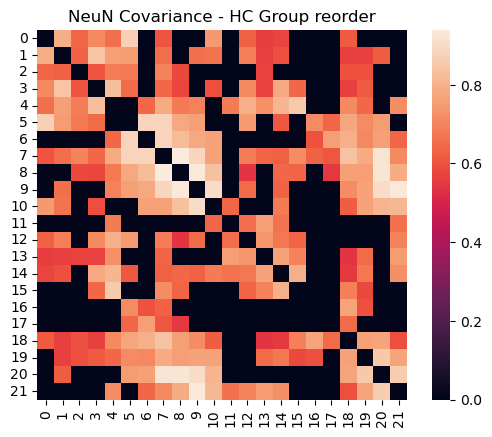

<Figure size 640x480 with 0 Axes>

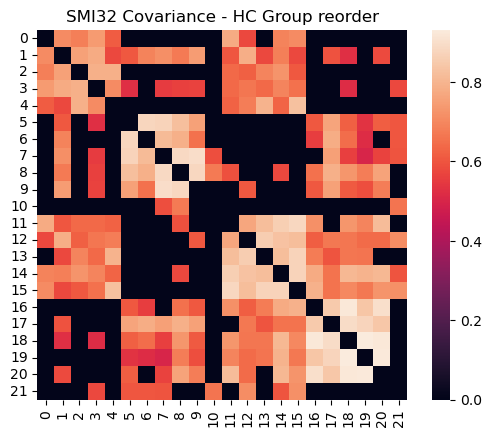

<Figure size 640x480 with 0 Axes>

In [108]:
# REORDER TO MATCH THE NEW DATA
reorder_inds = np.concatenate((np.arange(0,11)*2, np.arange(0,11)*2+1))

print("------- Original Node names -------")
print(node_names)

print("------- New Node names -------")
print(node_names[reorder_inds])

print("------- Node Atlas From New Data -------")
print(node_atlas)

HC_NeuN_sig_network_OLD_reorder = HC_NeuN_sig_network_OLD[reorder_inds][:, reorder_inds]
HC_SMI32_sig_network_OLD_reorder = HC_SMI32_sig_network_OLD[reorder_inds][:, reorder_inds]

tau_patho_avg_OLD_reorder = tau_patho_avg_OLD[reorder_inds]
tdp_patho_avg_OLD_reorder = tdp_patho_avg_OLD[reorder_inds]

print(tau_patho_avg_OLD_reorder)
print(tdp_patho_avg_OLD_reorder)

plt.figure()
sns.heatmap(HC_NeuN_sig_network_OLD_reorder, square=True)
plt.title("NeuN Covariance - HC Group reorder")
plt.figure()

plt.figure()
sns.heatmap(HC_SMI32_sig_network_OLD_reorder, square=True)
plt.title("SMI32 Covariance - HC Group reorder")
plt.figure()

In [112]:
old_nets_old_patho = full_test(tau_patho_avg_OLD_reorder, tdp_patho_avg_OLD_reorder, HC_NeuN_sig_network_OLD_reorder, HC_SMI32_sig_network_OLD_reorder)

In [113]:
old_nets_new_patho = full_test(tau_patho_avg, tdp_patho_avg, HC_NeuN_sig_network_OLD_reorder, HC_SMI32_sig_network_OLD_reorder)

In [114]:
new_nets_old_patho = full_test(tau_patho_avg_OLD_reorder, tdp_patho_avg_OLD_reorder, HC_NeuN_sig_network, HC_SMI32_sig_network)

In [115]:
new_nets_new_patho = full_test(tau_patho_avg, tdp_patho_avg, HC_NeuN_sig_network, HC_SMI32_sig_network)

In [116]:
# Report plots in a more organized manner
def plot_diffusion_ax(sim_spread, avg_pathology, group, color_scatter, color_line, ax):
    seed, time, optim_x_t = sim_spread
    performance = compute_performance(optim_x_t/np.max(optim_x_t), avg_pathology/np.max(avg_pathology))

    ax.scatter(optim_x_t/np.max(optim_x_t), avg_pathology/np.max(avg_pathology), color=color_scatter)

    ax.set_title(group + ' diffusion results, seed=(' + str(node_atlas[seed]) + '), r=' + str(performance['pearsonr'])[0:4], y=1.02, fontsize=18)
    patho_name = group.split()[0]
    ax.set_ylabel('Ground truth ' + patho_name + '\n distribution (normed)', fontsize=16, labelpad=15)
    ax.set_xlabel('Predicted pathology distribution', fontsize=16)

    slope = performance['slope']
    int = performance['int']
    linrange = np.linspace((optim_x_t/np.max(optim_x_t)).min()-0.05, (avg_pathology/np.max(avg_pathology)).max()+0.05, 100)
    ax.plot(linrange, linrange*slope+int, linestyle='dashed', color=color_line)

def plot_experiments(netdiff_results, tau_patho_avg, tdp_patho_avg):
    tau_neun = netdiff_results['Tau_NeuN']
    tau_smi32 = netdiff_results['Tau_SMI32']
    tdp_neun = netdiff_results['TDP_NeuN']
    tdp_smi32 = netdiff_results['TDP_SMI32']

    fig, ax = plt.subplots(2, 2, figsize=(15,15))
    plt.subplots_adjust(hspace=0.5, wspace=0.4) 
    plot_diffusion_ax(tdp_neun, tdp_patho_avg, 'TDP NeuN-HC-Unthresholded\n', 'C0', 'C0', ax[0,0])
    plot_diffusion_ax(tdp_smi32, tdp_patho_avg, 'TDP SMI32-HC-Unthresholded\n', 'C0', 'C0', ax[1,0])
    
    plot_diffusion_ax(tau_neun, tau_patho_avg, 'TAU NeuN-Unthresholded\n', 'tab:red', 'tab:red', ax[0,1])
    plot_diffusion_ax(tau_smi32, tau_patho_avg, 'TAU SMI32-HC-Unthresholded\n', 'tab:red', 'tab:red', ax[1,1])


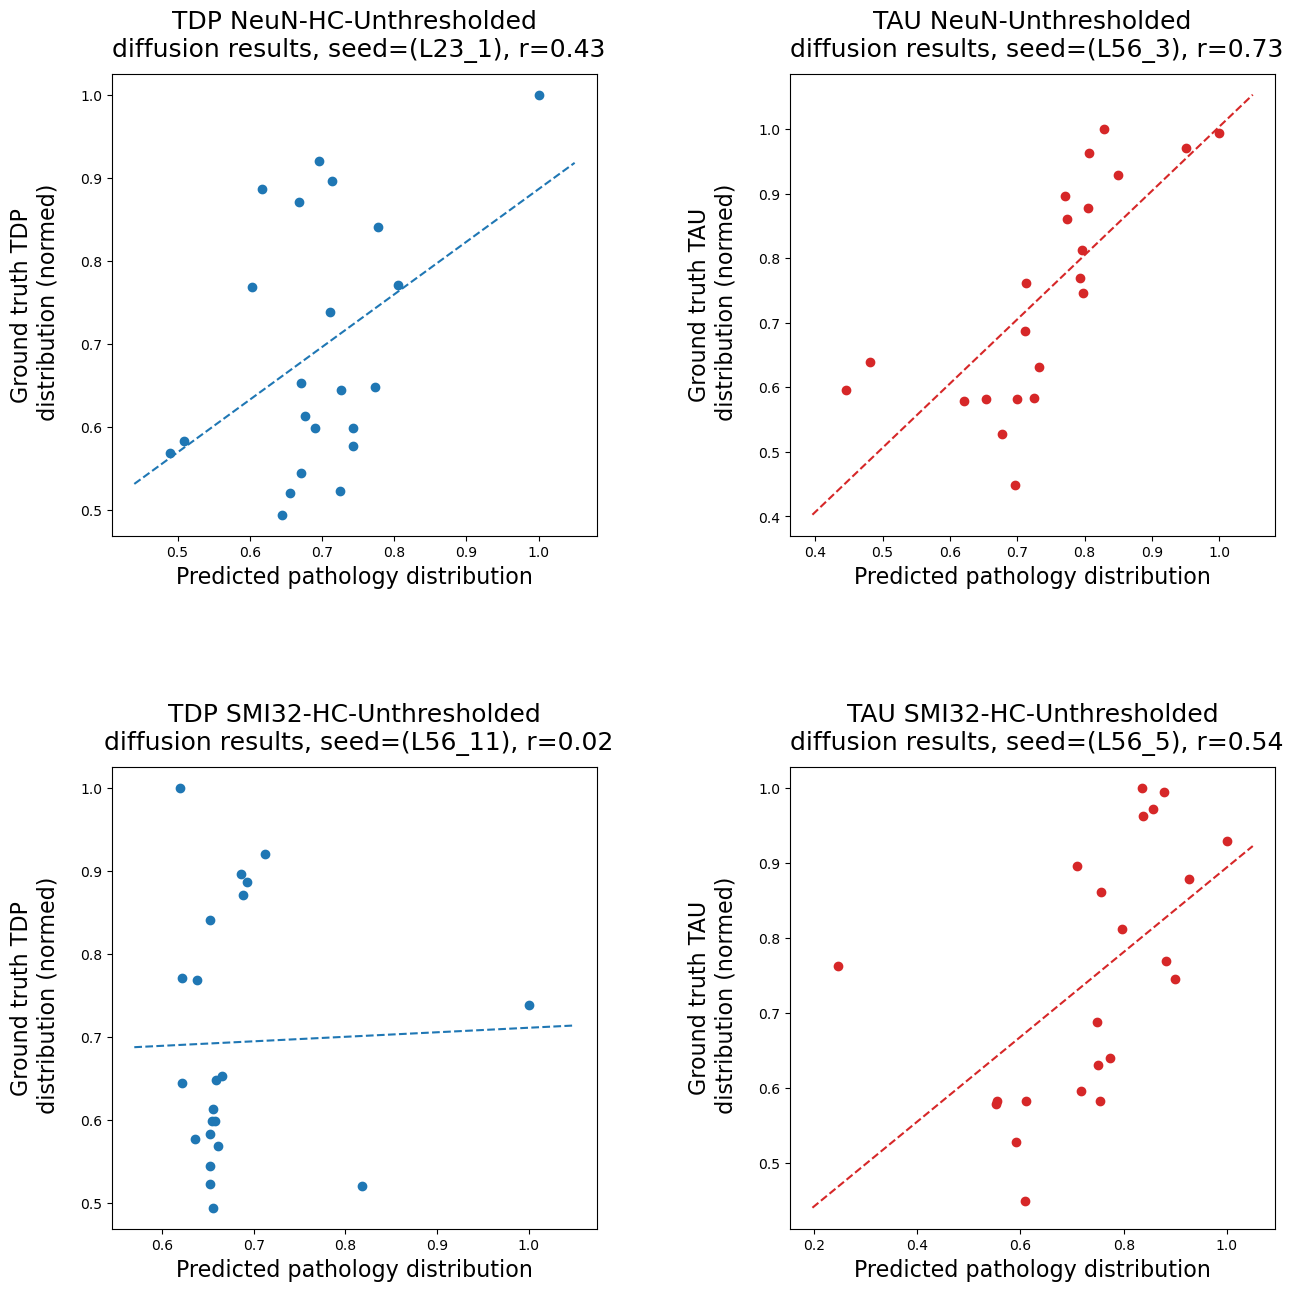

In [121]:
# Old nets, old pathology
plot_experiments(old_nets_old_patho, tau_patho_avg_OLD_reorder, tdp_patho_avg_OLD_reorder)

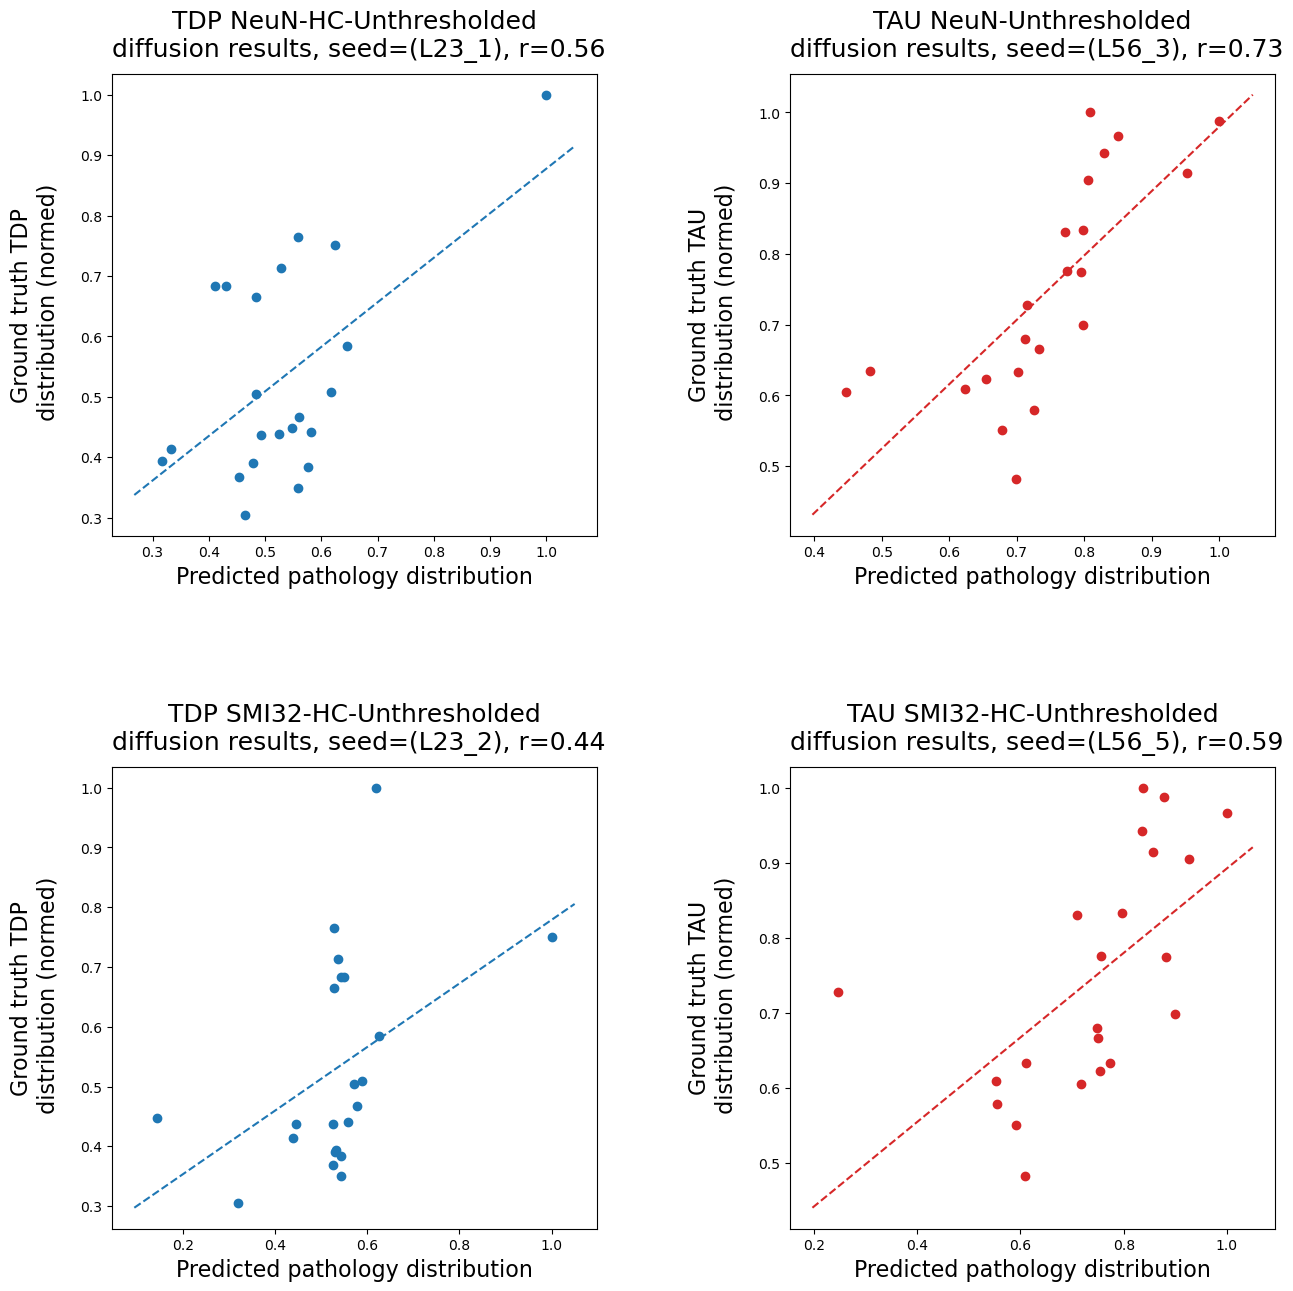

In [122]:
# Old nets, new pathology
plot_experiments(old_nets_new_patho, tau_patho_avg, tdp_patho_avg)

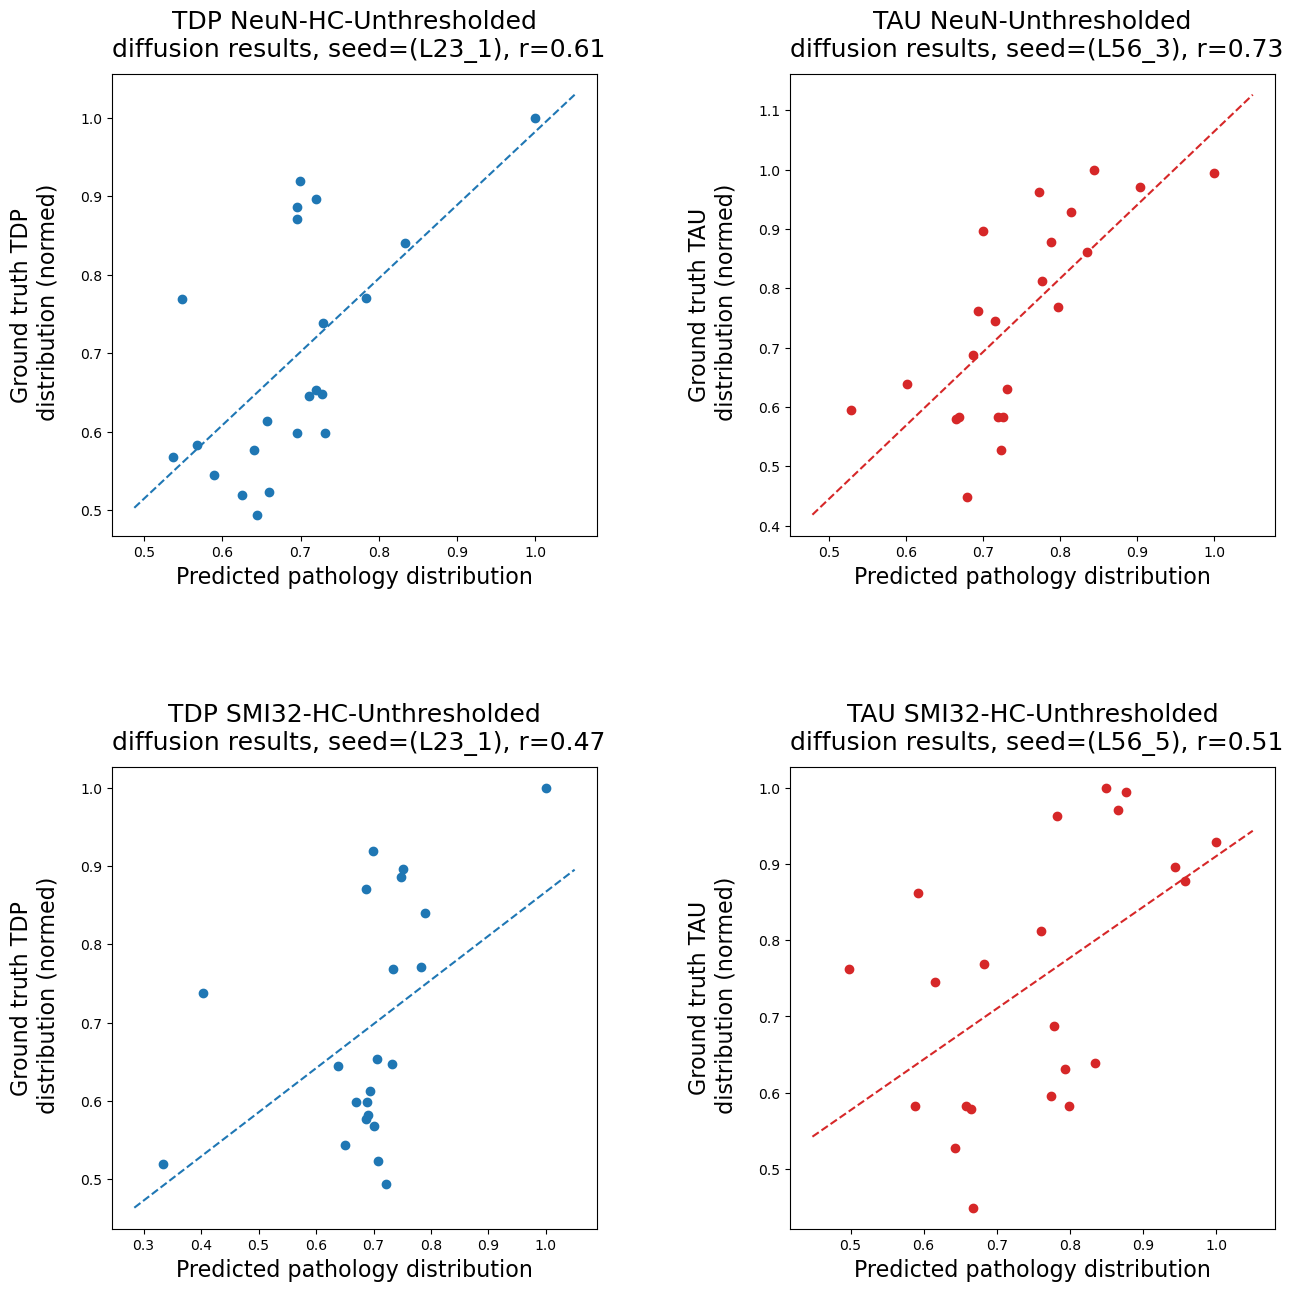

In [123]:
# New nets, old pathology
plot_experiments(new_nets_old_patho, tau_patho_avg_OLD_reorder, tdp_patho_avg_OLD_reorder)

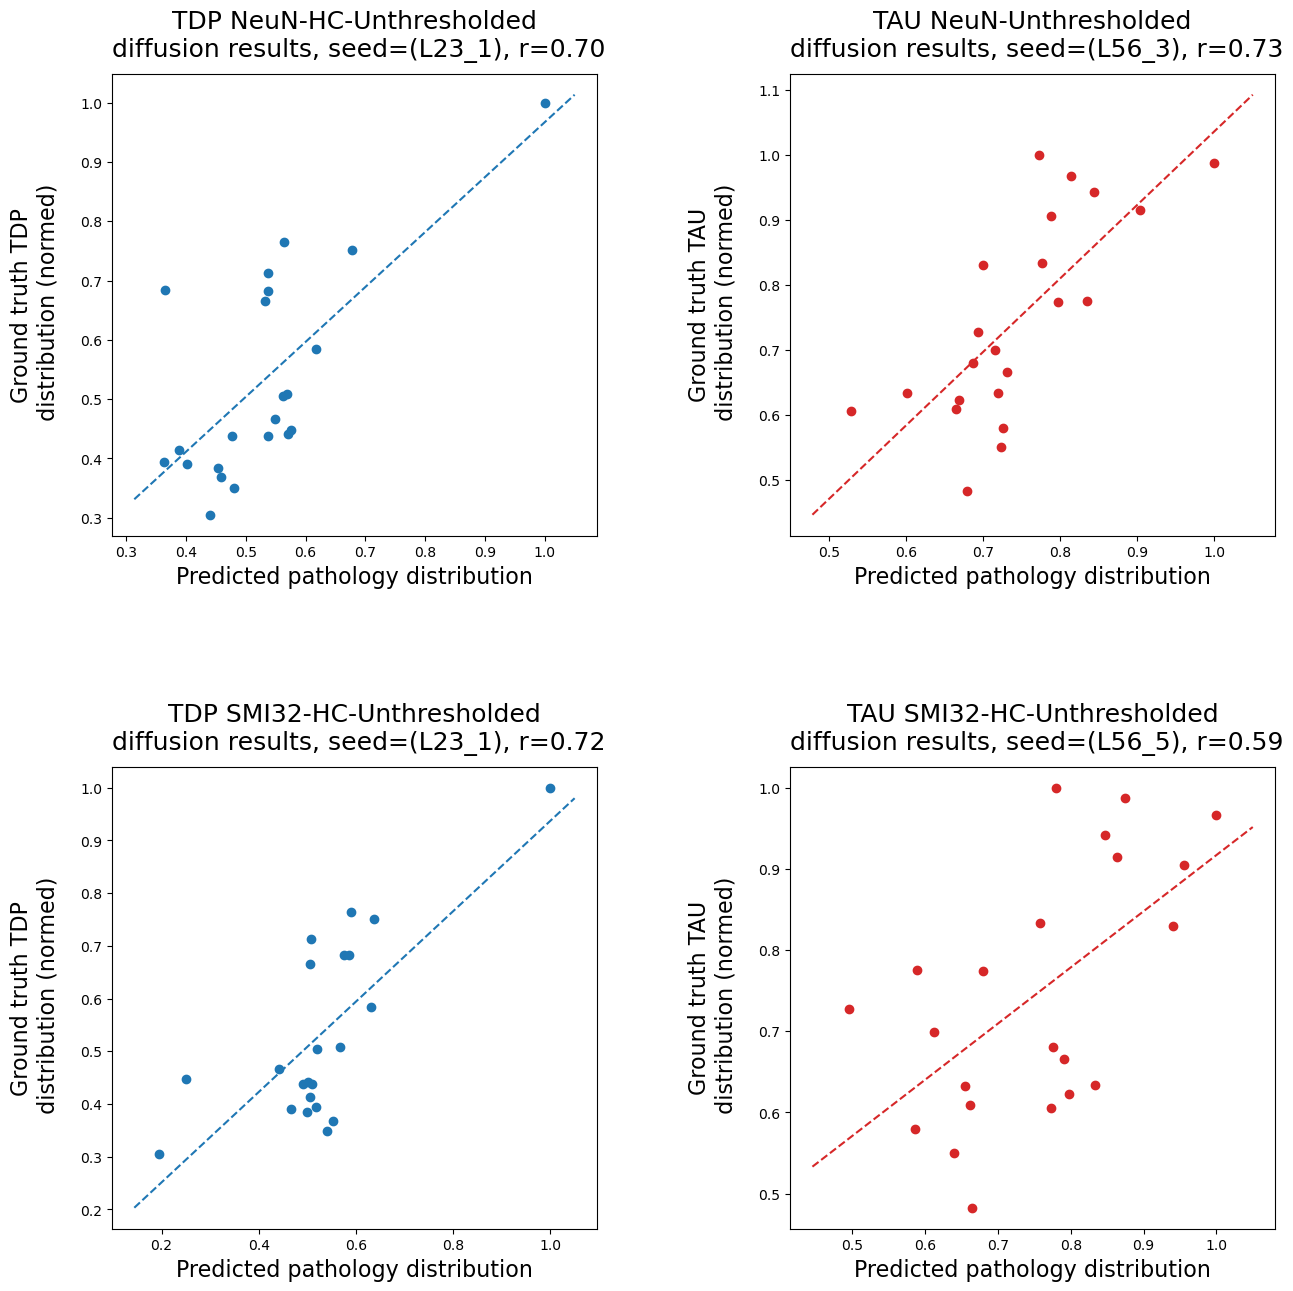

In [124]:
# New nets, new pathology
plot_experiments(new_nets_new_patho, tau_patho_avg, tdp_patho_avg)